## References and limitations addressed

**[1] Patoz, A., Malatesta, D., & Burtscher, J. (2023).**  
Isolating the speed factor is crucial in gait analysis for Parkinson's disease.  
*Frontiers in Neuroscience, 17*, 1119390.  
https://doi.org/10.3389/fnins.2023.1119390

**Application:** Informs the fourth-order, 15 Hz Butterworth filter and the use of temporal variability and asymmetry features. Our preprocessing is adapted rather than an exact replication.

**[2] Yogev, G., Plotnik, M., Peretz, C., Giladi, N., & Hausdorff, J. M. (2007).**  
Gait asymmetry in patients with Parkinson's disease and elderly fallers: when does the bilateral coordination of gait require attention?  
*Experimental Brain Research, 177*(3), 336–346.  
https://doi.org/10.1007/s00221-006-0676-3

**Application:** Supports the swing-time asymmetry calculation:

$$
\text{Swing asymmetry}
= 100 \times \left|\ln\left(
\frac{\text{mean right swing time}}{\text{mean left swing time}}
\right)\right|
$$

**[3] Kimmeskamp, S., & Hennig, E. M. (2001).**  
Heel to toe motion characteristics in Parkinson patients during free walking.  
*Clinical Biomechanics, 16*(9), 806–812.  
https://doi.org/10.1016/S0268-0033(01)00069-9

**Application:** Motivates our adapted heel/toe force peaks and regional load shares. These are force-based proxies rather than exact reproductions of the paper's pressure measurements.

### Limitations and our approach

As gait asymmetry also occurs in non-PD elderly fallers [2], we compare a stride-variability baseline with combined and reduced feature sets rather than relying on one gait descriptor alone. To examine generalisation beyond the small cohorts in [2, 3], we separate subjects during evaluation and test UPDRSM prediction on an unseen source study. Walking speed can confound gait comparisons [1]; although Task 1 includes `speed_01` as a predictor, this does not isolate speed effects, so speed confounding remains a limitation.

In [ ]:
# =====================================================================
# STEP 0: Imports and settings
# =====================================================================

# File handling
import glob
import os
import zipfile
import joblib
import sys
import sklearn
import scipy
import matplotlib
import seaborn as sns

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Signal processing and statistical analysis
from scipy.signal import butter, filtfilt, medfilt
from scipy.stats import pearsonr, spearmanr, f_oneway, kruskal

# Model preparation and feature selection
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.feature_selection import SelectKBest, RFE, f_regression

# Data splitting and model evaluation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    StratifiedGroupKFold,
    GroupKFold,
    LeaveOneGroupOut,
    GridSearchCV,
    cross_validate, cross_val_predict,
)

# Classification and regression models
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
)

# Performance metrics
from sklearn.metrics import (
    make_scorer, balanced_accuracy_score, classification_report,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Each walk file has 19 columns: time, 8 left-foot sensors, 8 right-foot sensors, 2 totals
left_sensors  = ['L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L7', 'L8']
right_sensors = ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8']
force_cols = left_sensors + right_sensors + ['Total_L', 'Total_R']
cols = ['Time'] + force_cols

# Position of each sensor along the foot, from format.txt (-800 = heel, +800 = toe)
sensor_y = np.array([-800, -400, -400, 0, 0, 400, 400, 800])

SEED = 42
print('Python:', sys.version.split()[0])
print('Package versions:', {
    'numpy': np.__version__, 'pandas': pd.__version__,
    'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__,
    'joblib': joblib.__version__,
})

Python: 3.13.18
Package versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'joblib': '1.6.0'}


In [ ]:
# =====================================================================
# STEP 1: Find and extract the walk files
# =====================================================================

def find_walk_files():
    files = []

    for path in sorted(glob.glob('**/*.txt', recursive=True)):
        name = os.path.basename(path)

        # Example filename: GaCo01_01.txt
        if (
            name[:2] in ('Ga', 'Ju', 'Si')
            and name[2:4] in ('Co', 'Pt')
            and '_' in name
        ):
            files.append(path)

    return files


walk_files = find_walk_files()

# Extract the archive if no walk files were found
if not walk_files:
    with zipfile.ZipFile('data.zip') as zf:
        zf.extractall('.')

    walk_files = find_walk_files()

print(f"{len(walk_files)} walk files found")

306 walk files found


In [ ]:
# =====================================================================
# STEP 2: Clean the subject metadata
# =====================================================================

# Find the metadata file, including inside subfolders (matching variations with suffixes)
meta_path = glob.glob('**/subject_metadata*.xls', recursive=True)[0]
meta = pd.read_excel(meta_path)
meta.columns = meta.columns.str.strip()

# Use shorter, consistent column names
meta = meta.rename(columns={
    'ID': 'subject_id',
    'Study': 'study',
    'Group': 'group',
    'Gender': 'gender',
    'Age': 'age',
    'Height (meters)': 'height_m',
    'Weight (kg)': 'weight_kg',
    'HoehnYahr': 'hy',
    'UPDRS': 'updrs',
    'UPDRSM': 'updrsm',
    'TUAG': 'tuag',
    'Speed_01 (m/sec)': 'speed_01',
})

# Clean subject IDs and keep one metadata row per subject
meta = meta.dropna(subset=['subject_id'])
meta['subject_id'] = meta['subject_id'].astype(str).str.strip()
meta['subject_id'] = meta['subject_id'].replace('Juc010', 'JuCo10')
meta = meta.drop_duplicates(subset='subject_id')

# Convert numeric fields; any invalid text becomes NaN
number_cols = [
    'age', 'height_m', 'weight_kg', 'hy',
    'updrs', 'updrsm', 'tuag', 'speed_01',
]

for col in number_cols:
    meta[col] = pd.to_numeric(meta[col], errors='coerce')

# Convert heights recorded in centimetres to metres
height_in_cm = meta['height_m'] > 3
meta.loc[height_in_cm, 'height_m'] = (
    meta.loc[height_in_cm, 'height_m'] / 100
)

# Inspect ranges and missing values before modelling
print("Minimum and maximum values:")
print(meta[number_cols].describe().loc[['min', 'max']])

print("\nMissing values:")
print(meta[number_cols].isna().sum())

Minimum and maximum values:
      age  height_m  weight_kg   hy  updrs  updrsm   tuag  speed_01
min  36.0      1.45       47.0  0.0    0.0     0.0   6.23     0.360
max  86.0      1.95      105.0  3.0   70.0    44.0  36.34     1.542

Missing values:
age           0
height_m      3
weight_kg     3
hy           55
updrs        31
updrsm       31
tuag         13
speed_01      1
dtype: int64


In [ ]:
# =====================================================================
# STEP 3: Function to clean one walk
# =====================================================================

# Fourth-order low-pass filter; 15 Hz cutoff informed by Patoz et al. (2023)
b, a = butter(4, 15, fs=100)


def clean_walk(walk):
    # Remove rows with missing values and sort by time
    walk = walk.dropna().sort_values('Time').reset_index(drop=True)

    if walk.empty:
        return None

    # Trim the first 10 seconds and last 5 seconds to reduce start/stop effects
    start = walk['Time'].iloc[0]
    end = walk['Time'].iloc[-1]
    keep = (walk['Time'] >= start + 10) & (walk['Time'] <= end - 5)
    walk = walk.loc[keep].reset_index(drop=True)

    # Skip walks too short for the filter's default padding
    min_samples = 3 * max(len(a), len(b)) + 1
    if len(walk) < min_samples:
        return None

    # Clean each sensor separately before calculating foot totals
    for col in left_sensors + right_sensors:
        signal = walk[col].to_numpy(dtype=float)
        signal = np.clip(signal, 0, None)          # Remove negative forces
        signal = medfilt(signal, kernel_size=5)    # Reduce brief spikes
        signal = filtfilt(b, a, signal)            # Smooth without shifting time
        walk[col] = np.clip(signal, 0, None)

    # Recalculate totals from the cleaned sensors
    walk['calc_Total_L'] = walk[left_sensors].sum(axis=1)
    walk['calc_Total_R'] = walk[right_sensors].sum(axis=1)

    # Normalise using the mean combined force across both feet
    mean_force = (walk['calc_Total_L'] + walk['calc_Total_R']).mean()

    if not np.isfinite(mean_force) or mean_force <= 0:
        return None

    scale_cols = left_sensors + right_sensors + [
        'calc_Total_L', 'calc_Total_R',
    ]
    walk[scale_cols] = walk[scale_cols] / mean_force

    # Restart the retained recording at zero seconds
    walk['Time'] = walk['Time'] - walk['Time'].iloc[0]

    return walk

In [ ]:
# =====================================================================
# STEP 4: Extract features from one cleaned walk
# =====================================================================

# Sensor regions (0-indexed), matching sensor_y from format.txt
HEEL_IDX = [0]       # sensor 1 (y = -800)
FORE_IDX = [5, 6]    # sensors 6-7 (y = +400)
TOE_IDX = [7]        # sensor 8 (y = +800)

plantar_names = ['heel_peak_bw', 'toe_peak_bw', 'rel_heel', 'rel_fore']


def plantar_load_features(sensor_forces, heel_strikes, valid_strides):
    """Per-stride plantar loading for one foot, summarised by the median.

    sensor_forces: (n_samples, 8) cleaned forces for one foot. Step 3 has
    already divided these by the walk's mean combined force, which
    approximates body weight, so peaks are in body-weight units.
    """
    # Use the same strides that passed the stride-time filter
    starts = heel_strikes[:-1][valid_strides]
    ends = heel_strikes[1:][valid_strides]

    rows = []
    for start, end in zip(starts, ends):
        stride = sensor_forces[start:end]
        impulse = stride.sum(axis=0)     # Force summed over the stride, per sensor
        total = impulse.sum()

        if total <= 0:
            continue

        rows.append([
            stride[:, HEEL_IDX].max(),            # Heel-strike peak
            stride[:, TOE_IDX].max(),             # Push-off peak
            impulse[HEEL_IDX].sum() / total,      # Share of load on the heel
            impulse[FORE_IDX].sum() / total,      # Share of load on the forefoot
        ])

    if not rows:
        return {name: np.nan for name in plantar_names}

    medians = np.median(np.array(rows), axis=0)
    return dict(zip(plantar_names, medians))


def mean_of_feet(left_value, right_value):
    """Average both feet, or use one foot if the other is missing."""
    values = [v for v in (left_value, right_value) if np.isfinite(v)]
    return np.mean(values) if values else np.nan


def make_features(walk):
    features = {}
    time = walk['Time'].to_numpy()
    on_ground = {}
    plantar = {}

    for foot in ['L', 'R']:
        total = walk['calc_Total_' + foot].to_numpy()

        if foot == 'L':
            foot_sensors = left_sensors
        else:
            foot_sensors = right_sensors

        # Estimate ground contact using 10% of the 95th-percentile force
        threshold = 0.1 * np.percentile(total, 95)
        ground = total > threshold
        on_ground[foot] = ground

        # Contact begins at 0 -> 1 and ends at 1 -> 0
        contact_changes = np.diff(ground.astype(int))
        heel_strikes = np.where(contact_changes == 1)[0] + 1
        toe_offs = np.where(contact_changes == -1)[0] + 1

        # Stride duration: time between consecutive contacts of the same foot
        stride_times = np.diff(time[heel_strikes])
        valid_strides = (stride_times > 0.4) & (stride_times < 2.5)
        stride_times = stride_times[valid_strides]

        # Plantar loading per stride, using the same valid strides
        plantar[foot] = plantar_load_features(
            walk[foot_sensors].to_numpy(dtype=float),
            heel_strikes,
            valid_strides,
        )

        features['stride_time_mean_' + foot] = (
            stride_times.mean() if len(stride_times) > 0 else np.nan
        )

        # Coefficient of variation: standard deviation divided by mean
        if len(stride_times) >= 2:
            features['stride_cv_' + foot] = stride_times.std() / stride_times.mean()
        else:
            features['stride_cv_' + foot] = np.nan

        # Swing duration: time from toe-off to the next contact
        swing_times = []

        for toe_off in toe_offs:
            next_strikes = heel_strikes[heel_strikes > toe_off]

            if len(next_strikes) > 0:
                duration = time[next_strikes[0]] - time[toe_off]
                if 0.2 < duration < 1.0:
                    swing_times.append(duration)

        swing_times = np.array(swing_times)

        features['swing_mean_' + foot] = (
            swing_times.mean() if len(swing_times) > 0 else np.nan
        )

        if len(swing_times) >= 2:
            features['swing_cv_' + foot] = swing_times.std() / swing_times.mean()
        else:
            features['swing_cv_' + foot] = np.nan

        # Centre of pressure along the foot during ground contact
        forces = walk.loc[ground, foot_sensors].to_numpy()
        cop = (forces * sensor_y).sum(axis=1) / total[ground]

        if len(cop) > 0:
            assert (
                cop.min() >= sensor_y.min() - 1e-6
                and cop.max() <= sensor_y.max() + 1e-6
            ), 'COP outside foot'

            features['cop_y_std_' + foot] = cop.std()
        else:
            features['cop_y_std_' + foot] = np.nan

        # Mean and standard deviation of each sensor
        for col in foot_sensors:
            features[col + '_mean'] = walk[col].mean()
            features[col + '_std'] = walk[col].std()

    # Compare ground-contact patterns across both feet
    left_stance = on_ground['L'].mean()
    right_stance = on_ground['R'].mean()

    features['double_support_ratio'] = np.mean(on_ground['L'] & on_ground['R'])
    features['stance_asymmetry'] = abs(left_stance - right_stance)
    '''features['force_asymmetry'] = abs(
        walk['calc_Total_L'].mean() - walk['calc_Total_R'].mean()
    )'''

    # Compare mean swing durations using the absolute log ratio
    left_swing = features['swing_mean_L']
    right_swing = features['swing_mean_R']

    if (
        np.isfinite(left_swing) and np.isfinite(right_swing)
        and left_swing > 0 and right_swing > 0
    ):
        features['swing_asymmetry'] = abs(np.log(right_swing / left_swing)) * 100
    else:
        features['swing_asymmetry'] = np.nan

    # Plantar loading features, averaged over both feet
    # (left-right differences are already covered by the asymmetry features)
    for name in plantar_names:
        features[name] = mean_of_feet(plantar['L'][name], plantar['R'][name])

    return features

# Feature sets used in the severity models
gait_cols = [
    'double_support_ratio',
    'stance_asymmetry',
    'stride_time_mean_L', 'stride_time_mean_R',
    'stride_cv_L', 'stride_cv_R',
    'swing_mean_L', 'swing_mean_R',
    'swing_cv_L', 'swing_cv_R',
    'swing_asymmetry',
    # Plantar loading features (Kimmeskamp & Hennig, 2001)
    'heel_peak_bw', 'toe_peak_bw',
    'rel_heel', 'rel_fore',
]

sensor_cols = []
for col in left_sensors + right_sensors:
    sensor_cols.append(col + '_mean')
    sensor_cols.append(col + '_std')

all_cols = gait_cols + sensor_cols

In [ ]:
# =====================================================================
# STEP 5: Build the walk-level and baseline datasets
# =====================================================================

records = []
excluded = []

for path in walk_files:
    name = os.path.basename(path)       # Example: GaPt05_01.txt
    study = name[:2]
    group = name[2:4]                   # Co = control, Pt = Parkinson's
    walk_num = name[7:9]

    walk = pd.read_csv(path, sep=r'\s+', header=None)

    # Check the number of columns before assigning names
    if walk.shape[1] != len(cols):
        excluded.append((name, 'wrong number of columns'))
        continue

    walk.columns = cols
    walk = walk.apply(pd.to_numeric, errors='coerce')

    # Flag constant sensor readings; retain these walks
    sensor_std = walk[left_sensors + right_sensors].std()
    dead_sensors = int((sensor_std == 0).sum())

    clean = clean_walk(walk)

    if clean is None:
        excluded.append((name, 'unusable after cleaning'))
        continue

    # Combine identifying information with the extracted features
    row = {
        'filename': name,
        'study': study,
        'subject_id': name[:6],
        'walk_num': walk_num,
        'label': 1 if group == 'Pt' else 0,
        'dead_sensors': dead_sensors,
    }
    row.update(make_features(clean))
    records.append(row)

# Report exclusions before constructing the dataset
print("Excluded walks:", len(excluded))
if excluded:
    display(pd.DataFrame(excluded, columns=['filename', 'reason']))

if not records:
    raise ValueError("No usable walks remain after cleaning.")

dataset_df = pd.DataFrame(records)

print(
    "Walks with constant sensor readings:",
    (dataset_df['dead_sensors'] > 0).sum(),
)

# Add metadata; study is already available from the filename
dataset_df = dataset_df.merge(
    meta.drop(columns='study'),
    on='subject_id',
    how='left',
    validate='many_to_one',
)

# Check for missing, unrecognised, or conflicting metadata group labels
meta_group = dataset_df['group'].astype(str).str.strip()
meta_label = meta_group.map({'PD': 1, 'CO': 0})
mismatch = dataset_df.loc[meta_label != dataset_df['label']]

print(
    "Missing or conflicting metadata labels:",
    mismatch['subject_id'].unique().tolist(),
)

# Use walk 01 as the baseline recording for each subject
base_df = dataset_df.loc[
    dataset_df['walk_num'] == '01'
].reset_index(drop=True)

assert base_df['subject_id'].is_unique, "Duplicate baseline subjects found."

print(f"{len(dataset_df)} walks in total, {len(base_df)} baseline walks")
print(pd.crosstab(base_df['study'], base_df['label']))

# Save both datasets
dataset_df.to_csv('all_walks_dataset.csv', index=False)
base_df.to_csv('baseline_dataset.csv', index=False)

Excluded walks: 0
Walks with constant sensor readings: 0
Missing or conflicting metadata labels: []
306 walks in total, 165 baseline walks
label   0   1
study        
Ga     18  29
Ju     25  29
Si     29  35


In [ ]:
# =====================================================================
# EDA: Body-weight normalization of sensor force features
# =====================================================================

import numpy as np

# Identify the 32 sensor-statistics columns
sensor_cols = []

for sensor in left_sensors + right_sensors:
    sensor_cols.extend([
        sensor + '_mean',
        sensor + '_std'
    ])

# Check actual weight column
print("Weight-related columns:")
print([c for c in dataset_df.columns if 'weight' in c.lower()
       or 'weigh' in c.lower()])

WEIGHT_COL = 'weight_kg'  # Change if necessary

# Verify required columns
assert WEIGHT_COL in dataset_df.columns
assert all(c in dataset_df.columns for c in sensor_cols)

# Body weight in Newtons
body_weight_N = dataset_df[WEIGHT_COL] * 9.81

# Invalid or zero weights should not be used
body_weight_N = body_weight_N.where(body_weight_N > 0)

# Create normalized force features
normalized_sensor_cols = []

for col in sensor_cols:
    new_col = col + '_norm'

    dataset_df[new_col] = (
        dataset_df[col] / body_weight_N
    )

    normalized_sensor_cols.append(new_col)

# Recreate baseline dataframe with new columns
base_df = dataset_df[
    dataset_df['walk_num'] == '01'
].reset_index(drop=True)

print("Normalized features created:",
      len(normalized_sensor_cols))

print("Example normalized columns:")
print(normalized_sensor_cols[:8])

# Save updated datasets
dataset_df.to_csv('all_walks_dataset.csv', index=False)
base_df.to_csv('baseline_dataset.csv', index=False)

Weight-related columns:
['weight_kg']
Normalized features created: 32
Example normalized columns:
['L1_mean_norm', 'L1_std_norm', 'L2_mean_norm', 'L2_std_norm', 'L3_mean_norm', 'L3_std_norm', 'L4_mean_norm', 'L4_std_norm']


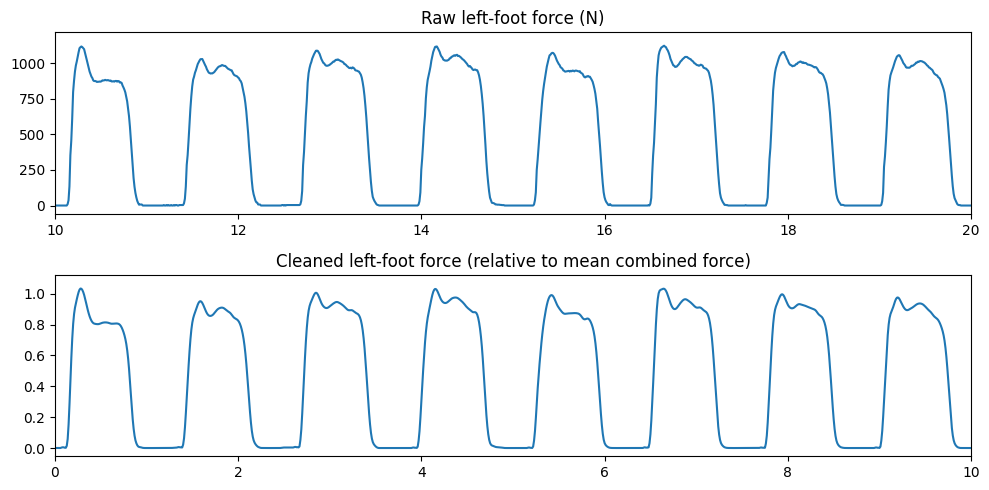

In [ ]:
# =====================================================================
# STEP 6: Picture for the presentation: one walk before and after cleaning
# =====================================================================
example = pd.read_csv(walk_files[0], sep=r'\s+', header=None, names=cols)
example_clean = clean_walk(example)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(example['Time'], example['Total_L'])
axes[0].set_title('Raw left-foot force (N)')
axes[0].set_xlim(10, 20)
axes[1].plot(example_clean['Time'], example_clean['calc_Total_L'])
axes[1].set_title('Cleaned left-foot force (relative to mean combined force)')
axes[1].set_xlim(0, 10)
plt.tight_layout()
plt.show()

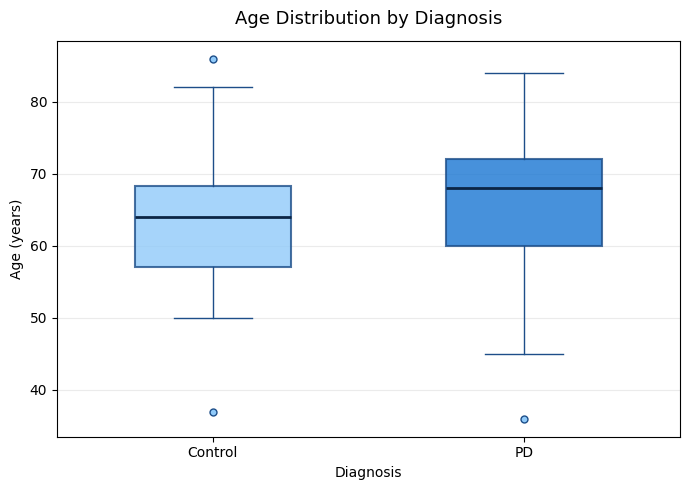

In [ ]:
# =====================================================================
# Data Visualisation: Age distribution by diagnosis
# =====================================================================

fig, ax = plt.subplots(figsize=(7, 5))

age_data = [
    df1.loc[df1['label'] == 0, 'age'].dropna(),
    df1.loc[df1['label'] == 1, 'age'].dropna(),
]

bp = ax.boxplot(
    age_data,
    tick_labels=['Control', 'PD'],
    patch_artist=True,
    widths=0.5,
    medianprops=dict(color='#0B2545', linewidth=2),
    boxprops=dict(edgecolor='#1D4E89', linewidth=1.5),
    whiskerprops=dict(color='#1D4E89'),
    capprops=dict(color='#1D4E89'),
    flierprops=dict(
        marker='o', markerfacecolor='#90CAF9',
        markeredgecolor='#1D4E89', markersize=5
    )
)

for patch, color in zip(bp['boxes'], ['#90CAF9', '#1976D2']):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.set_title('Age Distribution by Diagnosis', fontsize=13, pad=12)
ax.set_xlabel('Diagnosis')
ax.set_ylabel('Age (years)')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)


plt.tight_layout()
plt.savefig('fig_age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# ===================== STEP 7: Prepare data for Task 1 =====================

SEED = 42   # fixed random seed so results are the same every run

# 7a. The gait features we created in Step 5

FEATURES = [
    # Left foot
    'stride_cv_L', 'stride_time_mean_L', 'swing_mean_L', 'swing_cv_L',
    'L1_mean', 'L1_std', 'L2_mean', 'L2_std', 'L3_mean', 'L3_std', 'L4_mean', 'L4_std',
    'L5_mean', 'L5_std', 'L6_mean', 'L6_std', 'L7_mean', 'L7_std', 'L8_mean', 'L8_std',
    # Right foot
    'stride_cv_R', 'stride_time_mean_R', 'swing_mean_R', 'swing_cv_R',
    'R1_mean', 'R1_std', 'R2_mean', 'R2_std', 'R3_mean', 'R3_std', 'R4_mean', 'R4_std',
    'R5_mean', 'R5_std', 'R6_mean', 'R6_std', 'R7_mean', 'R7_std', 'R8_mean', 'R8_std',
    # Symmetry / global
    'double_support_ratio', 'stance_asymmetry',
    'swing_asymmetry',
    # Metadata
    'age', 'height_m', 'weight_kg', 'tuag', 'speed_01',
    # Plantar-loading features
    'heel_peak_bw', 'toe_peak_bw',
    'rel_heel', 'rel_fore',
]

print("Features used:", FEATURES)

# 7c. One row per subject
df1 = base_df[['subject_id', 'study', 'label'] + FEATURES].reset_index(drop=True)
y = df1['label'].astype(int)                     # 1 = PD, 0 = Control
X_base = df1[FEATURES]

print("\nNumber of subjects:", len(df1))
print(y.value_counts().rename({1: 'PD', 0: 'Control'}))

# 7d. Split subjects: 80% TRAIN, 20% TEST
# (stratify = keep the same PD/Control mix and study mix in both parts)
strata = df1['study'].astype(str) + '_' + y.astype(str)
train_idx, test_idx = train_test_split(df1.index, test_size=0.2,
                                       stratify=strata, random_state=SEED)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print("\nTrain subjects:", len(train_idx), "| Test subjects:", len(test_idx))

Features used: ['stride_cv_L', 'stride_time_mean_L', 'swing_mean_L', 'swing_cv_L', 'L1_mean', 'L1_std', 'L2_mean', 'L2_std', 'L3_mean', 'L3_std', 'L4_mean', 'L4_std', 'L5_mean', 'L5_std', 'L6_mean', 'L6_std', 'L7_mean', 'L7_std', 'L8_mean', 'L8_std', 'stride_cv_R', 'stride_time_mean_R', 'swing_mean_R', 'swing_cv_R', 'R1_mean', 'R1_std', 'R2_mean', 'R2_std', 'R3_mean', 'R3_std', 'R4_mean', 'R4_std', 'R5_mean', 'R5_std', 'R6_mean', 'R6_std', 'R7_mean', 'R7_std', 'R8_mean', 'R8_std', 'double_support_ratio', 'stance_asymmetry', 'swing_asymmetry', 'age', 'height_m', 'weight_kg', 'tuag', 'speed_01', 'heel_peak_bw', 'toe_peak_bw', 'rel_heel', 'rel_fore']

Number of subjects: 165
label
PD         93
Control    72
Name: count, dtype: int64

Train subjects: 132 | Test subjects: 33


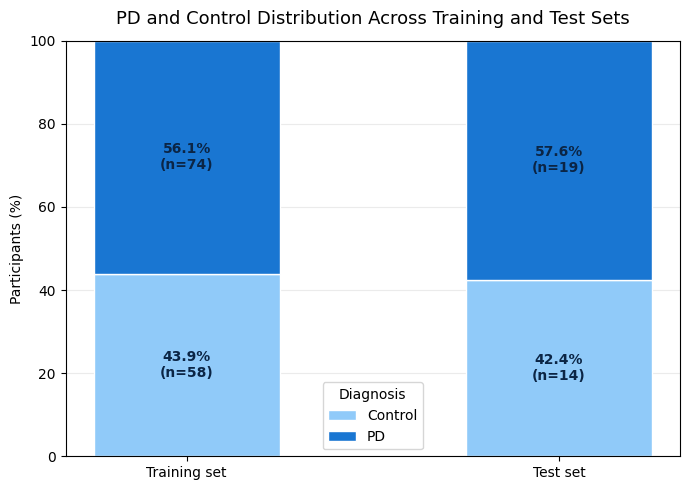

Participant counts:


,Training set,Test set
Control,58,14
PD,74,19


Participant percentages:


,Training set,Test set
Control,43.94,42.42
PD,56.06,57.58


In [ ]:

# =====================================================================
# Data Visualisation: PD and Control distribution across training and test sets
# =====================================================================

class_counts = pd.DataFrame({
    'Training set': y_train.value_counts().reindex([0, 1], fill_value=0),
    'Test set': y_test.value_counts().reindex([0, 1], fill_value=0),
})

class_counts.index = ['Control', 'PD']

class_percentages = class_counts.div(class_counts.sum(axis=0)) * 100

fig, ax = plt.subplots(figsize=(7, 5))

colors = ['#90CAF9', '#1976D2']
bottom = np.zeros(2)

for label, color in zip(['Control', 'PD'], colors):
    values = class_percentages.loc[label].values

    bars = ax.bar(
        ['Training set', 'Test set'],
        values,
        bottom=bottom,
        label=label,
        color=color,
        edgecolor='white',
        width=0.5
    )

    for bar, percentage, count in zip(
        bars, values, class_counts.loc[label].values
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_y() + bar.get_height() / 2,
            f'{percentage:.1f}%\n(n={count})',
            ha='center',
            va='center',
            fontsize=10,
            color='#0B2545',
            fontweight='bold'
        )

    bottom += values

ax.set_title('PD and Control Distribution Across Training and Test Sets',
             fontsize=13, pad=12)
ax.set_ylabel('Participants (%)')
ax.set_ylim(0, 100)
ax.legend(title='Diagnosis')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('fig_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Participant counts:")
display(class_counts)

print("Participant percentages:")
display(class_percentages.round(2))


In [ ]:
# =====================================================================
# STEP 8: Define evaluation metrics and the model pipeline
# =====================================================================

# The 6 scores we will report for every model
SCORING = {
    'Accuracy': 'accuracy',
    'Sensitivity': 'recall',                                     # % of PD patients correctly caught
    'Specificity': make_scorer(recall_score, pos_label=0),       # % of healthy people correctly cleared
    'Precision': make_scorer(precision_score, zero_division=0),  # when we say "PD", how often we're right
    'F1': make_scorer(f1_score, zero_division=0),                # balance of precision & sensitivity
    'AUC': 'roc_auc',                                            # ranking quality over ALL thresholds
}
METRICS = list(SCORING)

# Use five-fold cross-validation on the training subjects only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def get_cv_scores(model, X_train):
    """Return five validation scores for each metric."""
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
    )

    return {
        metric: results['test_' + metric]
        for metric in METRICS
    }

def get_test_scores(y_true, y_pred, y_prob):
    """Calculate the same metrics on the held-out test set."""
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Sensitivity': recall_score(y_true, y_pred),
        'Specificity': recall_score(y_true, y_pred, pos_label=0),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_true, y_prob),
    }

def logreg(k=None):
    """Build logistic regression with optional top-k feature selection."""
    steps = [
        SimpleImputer(strategy='median'),
        StandardScaler(),
    ]

    if k is not None:
        steps.append(SelectKBest(score_func=f_classif, k=k))

    steps.append(
        LogisticRegression(class_weight='balanced', max_iter=1000)
    )

    return make_pipeline(*steps)

In [ ]:
# STEP 8.5: Backward selection for M4


from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline

def logreg_rfe(k):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),

        ('rfe', RFE(
            estimator=LogisticRegression(
                class_weight='balanced',
                max_iter=1000
            ),
            n_features_to_select=k,
            step=1
        )),

        ('logreg', LogisticRegression(
            class_weight='balanced',
            max_iter=1000
        ))
    ])

In [ ]:
# =====================================================================
# STEP 9: Evaluate the baseline and full-feature models
# =====================================================================

STRIDE_COL = ['stride_cv_L', 'stride_cv_R']

# Exclude individual sensor summaries, leaving 21 gait and metadata features
SELECTION_FEATURES = [
    col for col in FEATURES if col not in sensor_cols
]
X_gait_meta = X_base[SELECTION_FEATURES]

# Each entry contains the model and its feature table for all subjects
models = {
    'M0 Guess majority': (
        DummyClassifier(strategy='most_frequent'),
        X_base,
    ),
    'M1 Stride variability only': (logreg(), X_base[STRIDE_COL]),
    'M2 All features': (logreg(), X_base),
    'M3 Gait + metadata': (logreg(), X_gait_meta),
}

# Evaluate using training subjects only
cv_results = {}

for name, (model, X_full) in models.items():
    scores = get_cv_scores(model, X_full.loc[train_idx])
    cv_results[name] = scores

    print(
        f"{name:30s} "
        f"CV accuracy = {scores['Accuracy'].mean():.3f} | "
        f"CV AUC = {scores['AUC'].mean():.3f}"
    )

M0 Guess majority              CV accuracy = 0.561 | CV AUC = 0.500
M1 Stride variability only     CV accuracy = 0.598 | CV AUC = 0.679
M2 All features                CV accuracy = 0.758 | CV AUC = 0.859
M3 Gait + metadata             CV accuracy = 0.788 | CV AUC = 0.872


In [ ]:
# =====================================================================
# EDA: Compare original vs normalized force features
# =====================================================================

normalization_models = {
    'Original 52 features': X_base[original_features],
    'Normalized 52 features': base_df[normalized_features]
}

normalization_results = {}

for name, X in normalization_models.items():

    scores = get_cv_scores(
        logreg(),
        X.loc[train_idx]
    )

    normalization_results[name] = scores

    print(
        f"{name}: "
        f"Accuracy = {scores['Accuracy'].mean():.3f}, "
        f"AUC = {scores['AUC'].mean():.3f}"
    )

Original 52 features: Accuracy = 0.758, AUC = 0.859
Normalized 52 features: Accuracy = 0.734, AUC = 0.862


In [ ]:
# =====================================================================
# EDA: Compare gait-only vs gait + metadata
# =====================================================================

# Five metadata features from Step 7
metadata_cols = [
    'age',
    'height_m',
    'weight_kg',
    'tuag',
    'speed_01'
]

# Three demographic features
demographic_cols = [
    'age',
    'height_m',
    'weight_kg'
]

# Remove metadata to obtain sensor-derived gait features
gait_only_cols = [
    col for col in FEATURES
    if col not in metadata_cols
]

# Create the three feature sets
feature_sets_comparison = {
    'Gait only (47)': gait_only_cols,
    'Gait + demographics (50)': gait_only_cols + demographic_cols,
    'Gait + all metadata (52)': FEATURES
}

# Verify feature counts
for name, cols in feature_sets_comparison.items():
    print(name, ":", len(cols), "features")
    assert all(col in X_base.columns for col in cols)

# Evaluate using training subjects only
comparison_results = []

for name, cols in feature_sets_comparison.items():

    X = X_base[cols]

    scores = get_cv_scores(
        logreg(),
        X.loc[train_idx]
    )

    comparison_results.append({
        'Feature Set': name,
        'Number of Features': len(cols),
        'Accuracy': scores['Accuracy'].mean(),
        'Sensitivity': scores['Sensitivity'].mean(),
        'Specificity': scores['Specificity'].mean(),
        'F1': scores['F1'].mean(),
        'AUC': scores['AUC'].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nGait-only vs Metadata Comparison")
display(comparison_df.round(3))

Gait only (47) : 47 features
Gait + demographics (50) : 50 features
Gait + all metadata (52) : 52 features

Gait-only vs Metadata Comparison


,Feature Set,Number of Features,Accuracy,Sensitivity,Specificity,F1,AUC
0,Gait only (47),47,0.735,0.784,0.671,0.772,0.809
1,Gait + demographics (50),50,0.742,0.796,0.671,0.776,0.806
2,Gait + all metadata (52),52,0.758,0.783,0.726,0.783,0.859


In [ ]:
print("Total features:", len(FEATURES))

print("\nAll features:")
for i, col in enumerate(FEATURES, 1):
    print(i, col)

print("\nDuplicate features:")
print(pd.Series(FEATURES)[pd.Series(FEATURES).duplicated()].tolist())

Total features: 52

All features:
1 stride_cv_L
2 stride_time_mean_L
3 swing_mean_L
4 swing_cv_L
5 L1_mean
6 L1_std
7 L2_mean
8 L2_std
9 L3_mean
10 L3_std
11 L4_mean
12 L4_std
13 L5_mean
14 L5_std
15 L6_mean
16 L6_std
17 L7_mean
18 L7_std
19 L8_mean
20 L8_std
21 stride_cv_R
22 stride_time_mean_R
23 swing_mean_R
24 swing_cv_R
25 R1_mean
26 R1_std
27 R2_mean
28 R2_std
29 R3_mean
30 R3_std
31 R4_mean
32 R4_std
33 R5_mean
34 R5_std
35 R6_mean
36 R6_std
37 R7_mean
38 R7_std
39 R8_mean
40 R8_std
41 double_support_ratio
42 stance_asymmetry
43 swing_asymmetry
44 age
45 height_m
46 weight_kg
47 tuag
48 speed_01
49 heel_peak_bw
50 toe_peak_bw
51 rel_heel
52 rel_fore

Duplicate features:
[]


In [ ]:
new_features = [
    'heel_peak_bw',
    'toe_peak_bw',
    'rel_heel',
    'rel_fore'
]

print(base_df[new_features].describe())

print("\nCorrelation matrix:")
display(base_df[new_features].corr().round(3))

print("\nCheck whether relative forces sum to 1:")
print(
    (base_df['rel_heel'] + base_df['rel_fore']).describe()
)

       heel_peak_bw  toe_peak_bw    rel_heel    rel_fore
count    165.000000   165.000000  165.000000  165.000000
mean       0.312360     0.175206    0.142110    0.316461
std        0.111525     0.068920    0.066208    0.054646
min        0.039630     0.058368    0.020939    0.181038
25%        0.238384     0.123865    0.083013    0.279327
50%        0.321154     0.168422    0.146305    0.317954
75%        0.389389     0.216647    0.197264    0.356618
max        0.552533     0.405875    0.294592    0.449984

Correlation matrix:


,heel_peak_bw,toe_peak_bw,rel_heel,rel_fore
heel_peak_bw,1.000,-0.050,0.807,-0.069
toe_peak_bw,-0.050,1.000,-0.252,0.295
rel_heel,0.807,-0.252,1.000,-0.001
rel_fore,-0.069,0.295,-0.001,1.000



Check whether relative forces sum to 1:
count    165.000000
mean       0.458572
std        0.085812
min        0.275384
25%        0.379877
50%        0.478522
75%        0.524344
max        0.620076
dtype: float64


 Number of features  Mean CV AUC  Standard Error
                  1       0.7689          0.0541
                  2       0.8059          0.0526
                  3       0.8125          0.0467
                  4       0.8297          0.0447
                  5       0.8381          0.0388
                  6       0.8335          0.0409
                  7       0.8481          0.0297
                  8       0.8553          0.0273
                  9       0.8598          0.0271
                 10       0.8752          0.0235
                 11       0.8750          0.0240
                 12       0.8704          0.0240
                 13       0.8695          0.0227
                 14       0.8684          0.0233
                 15       0.8715          0.0268
                 16       0.8716          0.0261
                 17       0.8704          0.0268
                 18       0.8704          0.0268
                 19       0.8704          0.0268
                 20 

,Model,Features,Mean CV AUC,SD AUC
0,5 features (RFE),5,0.8853,0.0532
1,4 features (without TUAG),4,0.8892,0.0332
2,4 features (without speed),4,0.8624,0.0975
3,3 features (gait only),3,0.7786,0.0616


Final M4 number of features: 4
Final M4 features: ['swing_mean_R', 'swing_asymmetry', 'speed_01', 'rel_heel']
Final M4 exploratory CV AUC: 0.8892279942279941


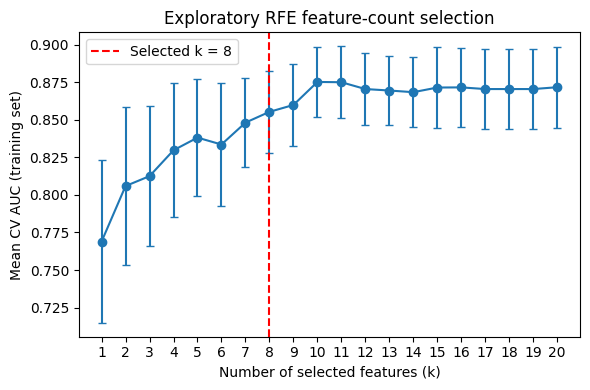

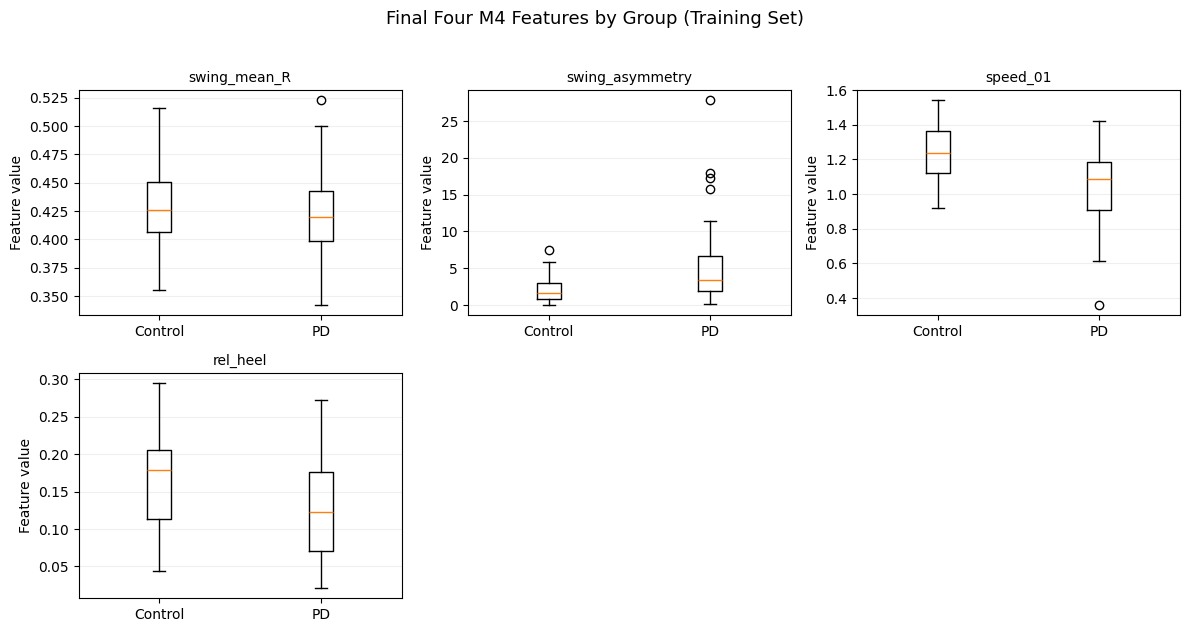

In [ ]:
# =====================================================================
# STEP 10: Select features from M3 to create M4
# =====================================================================

def choose_k_rfe(X_train):
    """Choose the smallest k within 1-SE of the best RFE CV AUC."""
    ks = np.arange(1, X_train.shape[1] + 1)
    aucs, ses = [], []

    for k in ks:
        scores = get_cv_scores(
            logreg_rfe(k), X_train
        )['AUC']

        aucs.append(scores.mean())
        ses.append(
            scores.std(ddof=1) / np.sqrt(len(scores))
        )

    aucs = np.array(aucs)
    ses = np.array(ses)

    best_idx = np.argmax(aucs)
    threshold = aucs[best_idx] - ses[best_idx]

    best_k = ks[np.where(aucs >= threshold)[0][0]]

    return best_k, ks, aucs, ses

# Display RFE performance for each feature count
results_df = pd.DataFrame({
    'Number of features': ks,
    'Mean CV AUC': aucs_m4,
    'Standard Error': ses_m4
})

print(results_df.round(4).to_string(index=False))
# Choose k using RFE + 1-SE rule
best_k, ks, aucs_m4, ses_m4 = choose_k_rfe(
    X_gait_meta.loc[train_idx]
)

# Fit RFE on training subjects
selected_model = logreg_rfe(best_k).fit(
    X_gait_meta.loc[train_idx], y_train
)

# Get selected features
selected_mask = selected_model.named_steps['rfe'].get_support()
kept = X_gait_meta.columns[selected_mask].tolist()

print("Selected number of features:", best_k)
print("Features kept:", kept)

# ===================== Compare RFE feature counts =====================

for k in [5, 8, 10]:
    model = logreg_rfe(k).fit(
        X_gait_meta.loc[train_idx],
        y_train
    )

    mask = model.named_steps['rfe'].get_support()
    features = X_gait_meta.columns[mask].tolist()

    print(f"\nk = {k}")
    print("Selected features:", features)
    print("Mean CV AUC:", round(aucs_m4[k - 1], 4))

# ===================== Explore smaller feature subsets =====================

feature_sets = {
    '5 features (RFE)': [
        'swing_mean_R',
        'swing_asymmetry',
        'tuag',
        'speed_01',
        'rel_heel'
    ],

    '4 features (without TUAG)': [
        'swing_mean_R',
        'swing_asymmetry',
        'speed_01',
        'rel_heel'
    ],

    '4 features (without speed)': [
        'swing_mean_R',
        'swing_asymmetry',
        'tuag',
        'rel_heel'
    ],

    '3 features (gait only)': [
        'swing_mean_R',
        'swing_asymmetry',
        'rel_heel'
    ]
}

comparison = []

for name, features in feature_sets.items():

    scores = get_cv_scores(
        logreg(),
        X_gait_meta.loc[train_idx, features]
    )

    comparison.append({
        'Model': name,
        'Features': len(features),
        'Mean CV AUC': scores['AUC'].mean(),
        'SD AUC': scores['AUC'].std(ddof=1)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

# ===================== Final M4: Four selected features =====================

final_features = [
    'swing_mean_R',
    'swing_asymmetry',
    'speed_01',
    'rel_heel'
]

# Use only the four selected features
X_m4 = X_gait_meta[final_features].copy()

# Logistic regression without additional RFE selection
models['M4 Feature-selected'] = (
    logreg(),
    X_m4
)

# Training-set CV for the fixed four-feature model
cv_results['M4 Feature-selected'] = get_cv_scores(
    logreg(),
    X_m4.loc[train_idx]
)

print("Final M4 number of features:", len(final_features))
print("Final M4 features:", final_features)
print(
    "Final M4 exploratory CV AUC:",
    cv_results['M4 Feature-selected']['AUC'].mean()
)

# Plot mean AUC with standard-error bars
plt.figure(figsize=(6, 4))
plt.errorbar(ks, aucs_m4, yerr=ses_m4, fmt='-o', capsize=3)
plt.axvline(
    best_k, color='red', linestyle='--',
    label=f'Selected k = {best_k}',
)
plt.xticks(ks)
plt.xlabel('Number of selected features (k)')
plt.ylabel('Mean CV AUC (training set)')
plt.title('Exploratory RFE feature-count selection')
plt.legend()
plt.tight_layout()
plt.savefig('choose_k.png', dpi=300)
plt.show()

# Show final four M4 features by PD/control group
kept = final_features.copy()

train_plot = df1.loc[train_idx]


ncols = 3
nrows = (len(kept) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(12, 3.2 * nrows),
    squeeze=False,
)

for ax, feature in zip(axes.ravel(), kept):
    control_values = train_plot.loc[
        train_plot['label'] == 0, feature
    ].dropna()

    pd_values = train_plot.loc[
        train_plot['label'] == 1, feature
    ].dropna()

    ax.boxplot(
        [control_values, pd_values],
        tick_labels=['Control', 'PD'],
    )
    ax.set_title(feature, fontsize=10)
    ax.set_ylabel('Feature value')
    ax.grid(axis='y', alpha=0.2)

# Hide unused panels
for ax in axes.ravel()[len(kept):]:
    ax.axis('off')

fig.suptitle(
    'Final Four M4 Features by Group (Training Set)',
    fontsize=13
)

fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig('fig_task1_features_by_group.png', dpi=300)
plt.show()

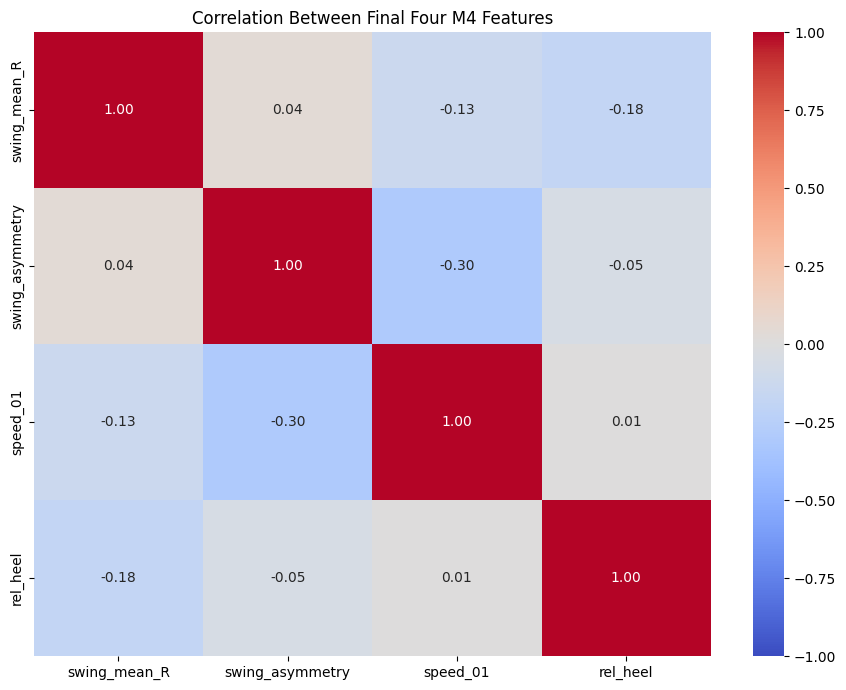

In [ ]:
# ===================== Correlation of final M4 features =====================

import seaborn as sns

corr = X_m4.loc[train_idx].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Between Final Four M4 Features')
plt.tight_layout()
plt.show()

TABLE 1: Five-fold CV on training subjects (mean)


,Accuracy,Sensitivity,Specificity,Precision,F1,AUC
M0 Guess majority,0.561,1.000,0.000,0.561,0.718,0.500
M1 Stride variability only,0.598,0.487,0.738,0.710,0.571,0.679
M2 All features,0.758,0.783,0.726,0.785,0.783,0.859
M3 Gait + metadata,0.788,0.783,0.798,0.835,0.806,0.872
M4 Feature-selected,0.818,0.798,0.847,0.874,0.828,0.889


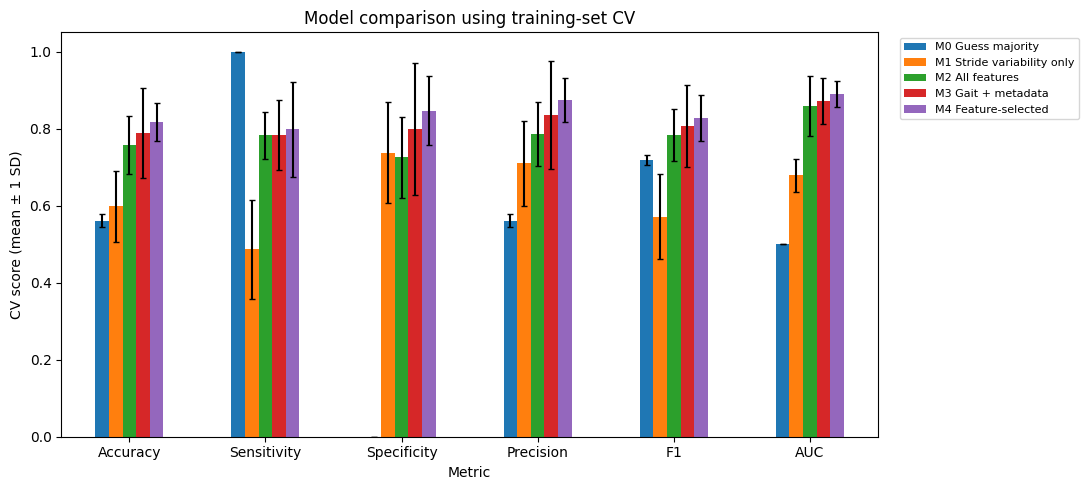


Chosen final model: M4 Feature-selected
Features reduced from 20 to 4
M3 CV AUC: 0.872
M4 CV AUC: 0.889


In [ ]:
# =====================================================================
# STEP 11: Compare models using training-set cross-validation
# =====================================================================

# Create separate tables for mean scores and standard deviations
cv_mean = pd.DataFrame(
    index=list(cv_results), columns=METRICS, dtype=float
)
cv_std = cv_mean.copy()

for name, scores in cv_results.items():
    for metric in METRICS:
        cv_mean.loc[name, metric] = scores[metric].mean()
        cv_std.loc[name, metric] = scores[metric].std(ddof=1)

# Display and save the mean scores
print("TABLE 1: Five-fold CV on training subjects (mean)")
display(cv_mean.round(3))
cv_mean.round(3).to_csv('table1_cv.csv')

# Compare all metrics, with error bars showing one standard deviation
ax = cv_mean.T.plot.bar(
    yerr=cv_std.T,
    figsize=(11, 5),
    rot=0,
    capsize=2,
)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Metric')
ax.set_ylabel('CV score (mean ± 1 SD)')
ax.set_title('Model comparison using training-set CV')
ax.legend(
    loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8
)

plt.tight_layout()
plt.savefig('cv_all_metrics.png', dpi=300)
plt.show()

# Deliberately choose M4 to investigate whether a smaller feature set
# can retain predictive performance comparable to M3.
# This choice is justified using training-set CV and feature count.
FINAL = 'M4 Feature-selected'

print(f"\nChosen final model: {FINAL}")
print(
    f"Features reduced from {X_gait_meta.shape[1]} "
    f"to {len(final_features)}"
)
print(
    f"M3 CV AUC: "
    f"{cv_mean.loc['M3 Gait + metadata', 'AUC']:.3f}"
)
print(
    f"M4 CV AUC: "
    f"{cv_mean.loc[FINAL, 'AUC']:.3f}"
)

TABLE 2: Held-out test set (33 subjects)


,Accuracy,Sensitivity,Specificity,Precision,F1,AUC
M0 Guess majority,0.576,1.000,0.000,0.576,0.731,0.500
M1 Stride variability only,0.455,0.421,0.500,0.533,0.471,0.508
M2 All features,0.939,0.947,0.929,0.947,0.947,0.981
M3 Gait + metadata,0.909,0.895,0.929,0.944,0.919,0.959
M4 Feature-selected,0.909,0.895,0.929,0.944,0.919,0.962


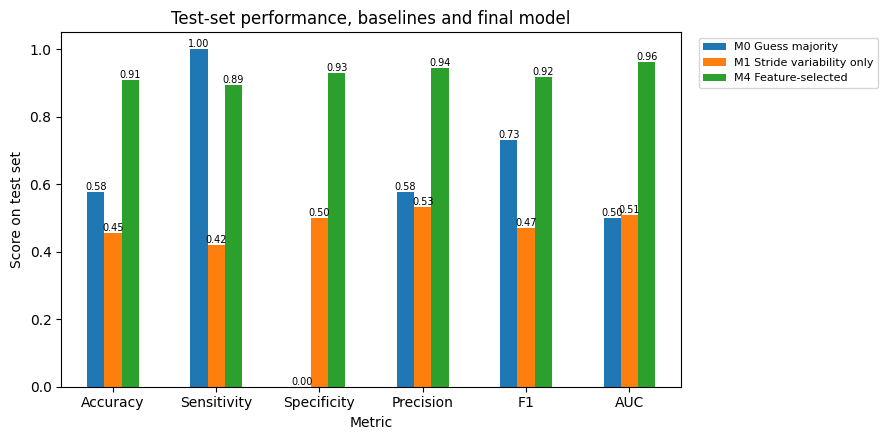

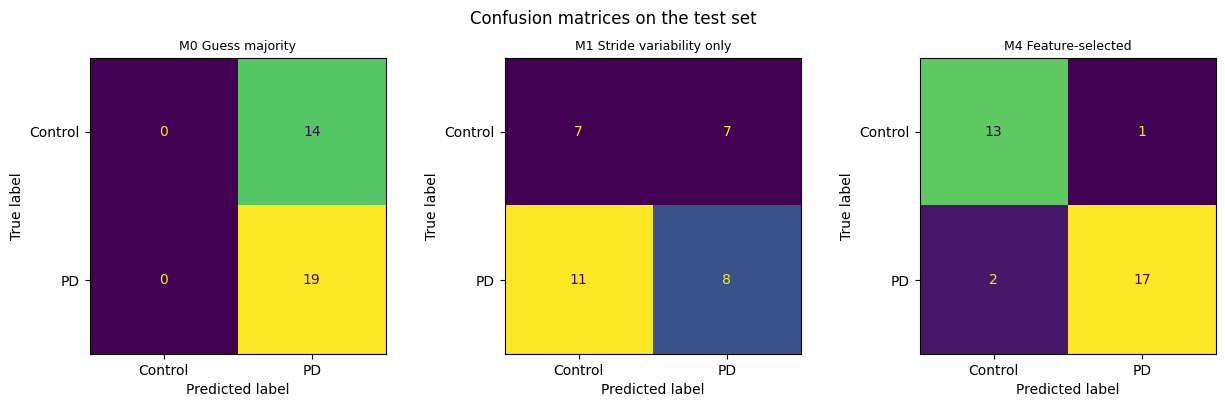

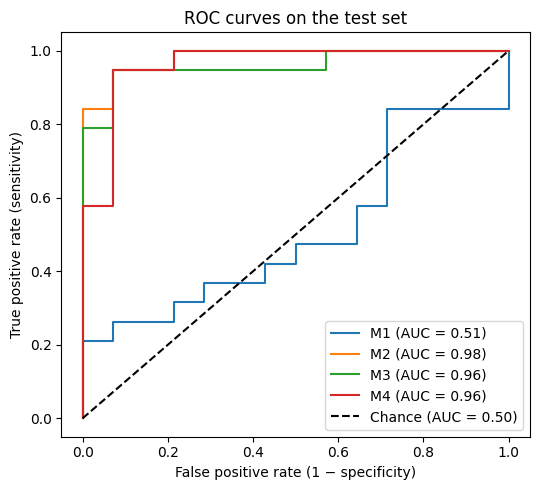

Saved Task 1 models.


In [ ]:
# =====================================================================
# STEP 12: Evaluate models on the held-out test set
# =====================================================================

# M4 was manually chosen in Step 11 for its smaller feature set
# and comparable training-set CV performance.
# Evaluate all models for comparison; retain M4 as the final model.

fitted = {}
test_pred = {}
test_prob = {}
test_rows = {}

# Refit each model using all training subjects
for name, (model, X_full) in models.items():
    trained_model = clone(model)
    trained_model.fit(X_full.loc[train_idx], y_train)

    fitted[name] = trained_model
    test_pred[name] = trained_model.predict(X_full.loc[test_idx])
    test_prob[name] = trained_model.predict_proba(X_full.loc[test_idx])[:, 1]

    test_rows[name] = get_test_scores(
        y_test, test_pred[name], test_prob[name]
    )

# Display and save results for all five models
test_table = pd.DataFrame(test_rows).T

print(f"TABLE 2: Held-out test set ({len(test_idx)} subjects)")
display(test_table.round(3))
test_table.round(3).to_csv('table2_test.csv')

# Show the baselines and M4, our manually chosen reduced-feature model
show = ['M0 Guess majority', 'M1 Stride variability only']
if FINAL not in show:
    show.append(FINAL)

# Figure 3: test-set metrics
ax = test_table.loc[show].T.plot.bar(figsize=(9, 4.5), rot=0)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Metric')
ax.set_ylabel('Score on test set')
ax.set_title('Test-set performance, baselines and final model')
ax.legend(
    loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8
)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f', fontsize=7)

plt.tight_layout()
plt.savefig('test_metrics.png', dpi=300)
plt.show()

# Figure 4: confusion matrices
fig, axes = plt.subplots(
    1, len(show), figsize=(4.2 * len(show), 4)
)

for ax, name in zip(axes, show):
    cm = confusion_matrix(y_test, test_pred[name], labels=[0, 1])

    ConfusionMatrixDisplay(
        cm, display_labels=['Control', 'PD']
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name, fontsize=9)

fig.suptitle('Confusion matrices on the test set')
plt.tight_layout()
plt.savefig('confusion.png', dpi=300)
plt.show()

# Figure 5: ROC curves for M1–M4
plt.figure(figsize=(5.5, 5))

for name in models:
    if name.startswith('M0'):
        continue

    fpr, tpr, _ = roc_curve(y_test, test_prob[name])
    model_id = name.split()[0]
    auc = test_table.loc[name, 'AUC']

    plt.plot(fpr, tpr, label=f'{model_id} (AUC = {auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.50)')
plt.xlabel('False positive rate (1 − specificity)')
plt.ylabel('True positive rate (sensitivity)')
plt.title('ROC curves on the test set')
plt.legend()
plt.tight_layout()
plt.savefig('roc.png', dpi=300)
plt.show()

# Save the fitted pipelines and their required input columns
task1_saved = {
    'models': fitted,
    'features': {
        name: X_full.columns.tolist()
        for name, (_, X_full) in models.items()
    },
    'final_model_name': FINAL,
    'test_subject_ids': df1.loc[test_idx, 'subject_id'].tolist(),
}

joblib.dump(task1_saved, 'task1_models.joblib', compress=3)
print("Saved Task 1 models.")

Model odds ratios per one training-set SD increase:
speed_01           0.24
rel_heel           0.36
swing_mean_R       0.47
swing_asymmetry    2.98
dtype: float64


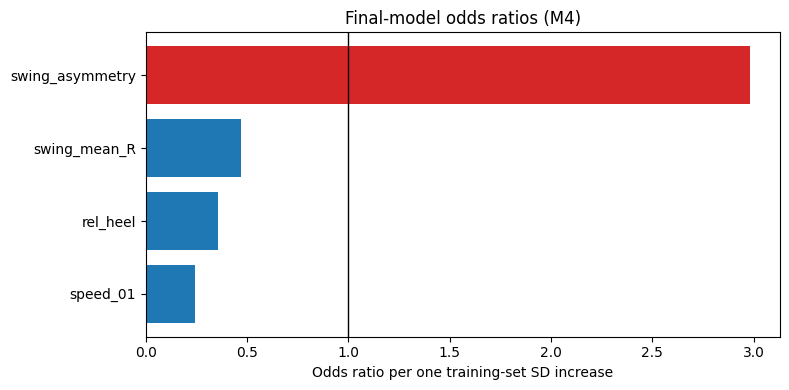

In [ ]:
# =====================================================================
# STEP 13: Interpret final M4
# =====================================================================

final_model = fitted[FINAL]

# Coefficients from logistic regression
coefficients = final_model.named_steps[
    'logisticregression'
].coef_[0]

# Feature names after imputation
imputer = final_model.named_steps['simpleimputer']
feature_names = imputer.get_feature_names_out()

# Verify that the model uses exactly four features
assert list(feature_names) == final_features
assert len(feature_names) == len(coefficients)

# Convert logistic regression coefficients into odds ratios
odds_ratios = pd.Series(
    np.exp(coefficients), index=feature_names
).sort_values()

print("Model odds ratios per one training-set SD increase:")
print(odds_ratios.round(2))

# Figure 6: allow enough space for every feature label
plot_height = max(4, 0.3 * len(odds_ratios))
colors = [
    'tab:blue' if ratio < 1 else 'tab:red'
    for ratio in odds_ratios
]

plt.figure(figsize=(8, plot_height))
plt.barh(odds_ratios.index, odds_ratios.values, color=colors)
plt.axvline(1, color='black', linewidth=1)
plt.xlabel('Odds ratio per one training-set SD increase')
plt.title(f'Final-model odds ratios ({FINAL.split()[0]})')
plt.tight_layout()
plt.savefig('odds_ratios.png', dpi=300)
plt.show()

Q1. Availability of severity scores
PD subjects: 93
Valid UPDRSM: 91; missing: 2
Valid H&Y: 93; missing: 0
Valid on both: 91
Missing UPDRSM IDs: ['SiPt02', 'SiPt07']

Q2–Q3. Severity distributions and unrepresented stages
count    91.00
mean     19.32
std       7.66
min       5.00
25%      14.00
50%      19.00
75%      24.00
max      44.00
Name: updrsm, dtype: float64
           Count  Percentage (%)
H&Y stage                       
1.0            0             0.0
1.5            0             0.0
2.0           55            59.1
2.5           28            30.1
3.0           10            10.8
4.0            0             0.0
5.0            0             0.0
Unrepresented H&Y stages: [1.0, 1.5, 4.0, 5.0]


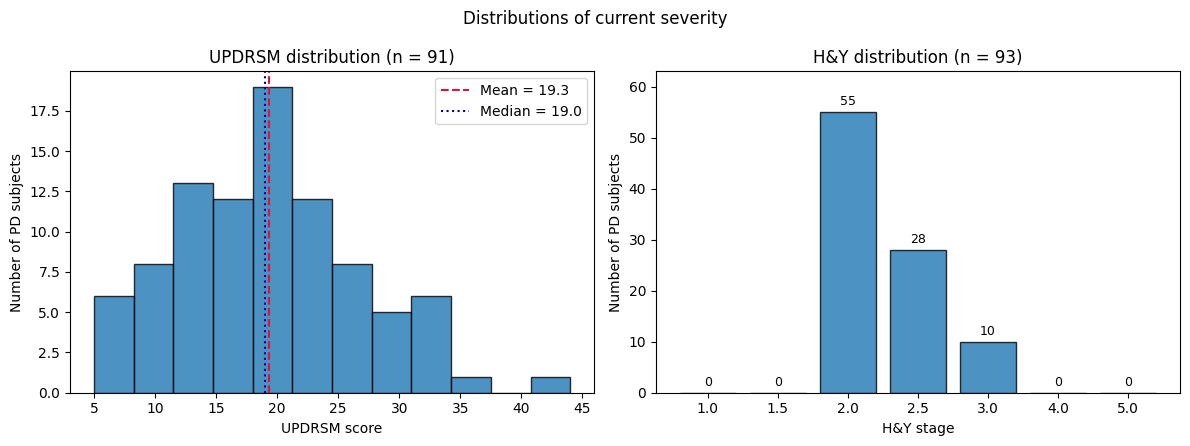


Q4. Gait-feature correlations with severity
             Feature  Pearson r (UPDRSM)  Pearson p (UPDRSM)  Spearman rho (UPDRSM)  Spearman p (UPDRSM)  Spearman rho (H&Y)  Spearman p (H&Y)
        heel_peak_bw              -0.161               0.128                 -0.142                0.178              -0.193            0.0636
  stride_time_mean_R               0.112               0.292                  0.117                0.267             -0.0368             0.726
            rel_fore                0.11               0.299                 0.0824                0.437               0.147             0.159
  stride_time_mean_L               0.108               0.306                  0.119                0.263             -0.0194             0.854
double_support_ratio               0.103               0.329                 0.0811                0.445               0.377          0.000193
        swing_mean_R               0.101               0.339                 0.0904              

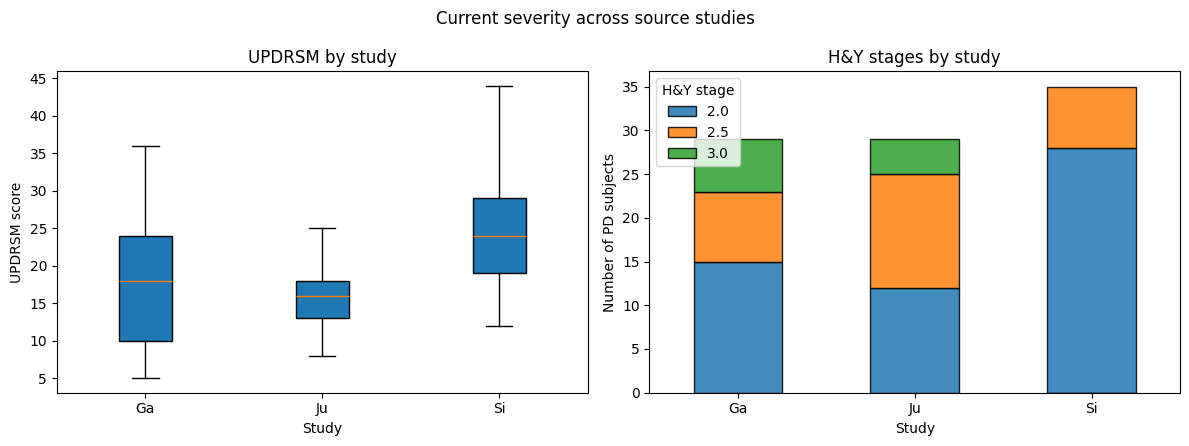

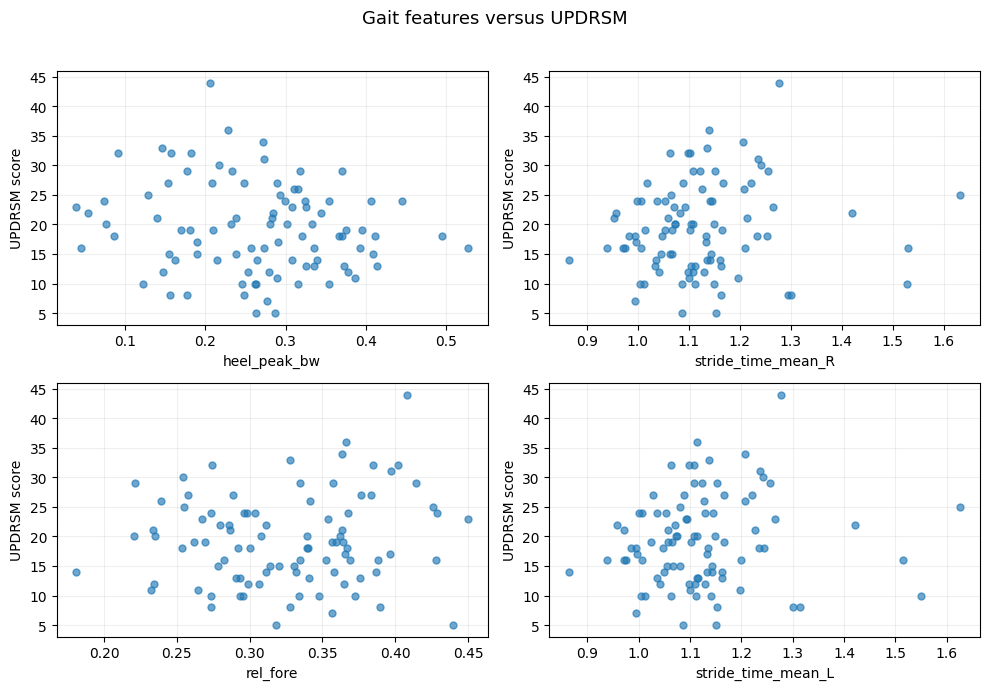

In [ ]:
# =====================================================================
# STEP 14: Explore current Parkinson's disease severity
# =====================================================================
# Scores describe current severity at the assessment visit.

pd_base = base_df.loc[base_df['label'] == 1].reset_index(drop=True)
pd_updrsm = pd_base.dropna(subset=['updrsm']).reset_index(drop=True)

# Q1: Availability of severity scores
n_pd_total = len(pd_base)
n_updrsm_valid = len(pd_updrsm)
n_hy_valid = pd_base['hy'].notna().sum()
both_valid = pd_base['updrsm'].notna() & pd_base['hy'].notna()

missing_updrsm_ids = pd_base.loc[
    pd_base['updrsm'].isna(), 'subject_id'
].tolist()

print("Q1. Availability of severity scores")
print("PD subjects:", n_pd_total)
print(f"Valid UPDRSM: {n_updrsm_valid}; missing: {n_pd_total - n_updrsm_valid}")
print(f"Valid H&Y: {n_hy_valid}; missing: {n_pd_total - n_hy_valid}")
print("Valid on both:", both_valid.sum())
print("Missing UPDRSM IDs:", missing_updrsm_ids)

# Q2–Q3: Distributions and unrepresented stages
print("\nQ2–Q3. Severity distributions and unrepresented stages")
updrsm_values = pd_updrsm['updrsm']
print(updrsm_values.describe().round(2))

hy_stages = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
hy_counts = pd_base['hy'].value_counts().reindex(hy_stages, fill_value=0)

hy_dist_df = pd.DataFrame({
    'Count': hy_counts,
    'Percentage (%)': (hy_counts / n_hy_valid * 100).round(1),
})
hy_dist_df.index.name = 'H&Y stage'

print(hy_dist_df)
print("Unrepresented H&Y stages:", hy_counts.index[hy_counts == 0].tolist())

# Figure 7: severity distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

mean_updrsm = updrsm_values.mean()
median_updrsm = updrsm_values.median()

axes[0].hist(updrsm_values, bins=12, edgecolor='black', alpha=0.8)
axes[0].axvline(
    mean_updrsm, color='crimson', linestyle='--',
    label=f'Mean = {mean_updrsm:.1f}',
)
axes[0].axvline(
    median_updrsm, color='navy', linestyle=':',
    label=f'Median = {median_updrsm:.1f}',
)
axes[0].set_title(f'UPDRSM distribution (n = {n_updrsm_valid})')
axes[0].set_xlabel('UPDRSM score')
axes[0].set_ylabel('Number of PD subjects')
axes[0].legend()

bars = axes[1].bar(
    hy_counts.index.astype(str), hy_counts.values,
    edgecolor='black', alpha=0.8,
)
axes[1].bar_label(bars, padding=3, fontsize=9)
axes[1].set_title(f'H&Y distribution (n = {n_hy_valid})')
axes[1].set_xlabel('H&Y stage')
axes[1].set_ylabel('Number of PD subjects')
axes[1].set_ylim(0, hy_counts.max() + 8)

fig.suptitle('Distributions of current severity')
plt.tight_layout()
plt.savefig('severity_distributions.png', dpi=300)
plt.show()

# Q4: Gait-feature correlations with severity
print("\nQ4. Gait-feature correlations with severity")
corr_records = []

for feature in gait_cols:
    updrsm_pairs = pd_base[[feature, 'updrsm']].dropna()
    hy_pairs = pd_base[[feature, 'hy']].dropna()

    pearson_r, pearson_p = pearsonr(
        updrsm_pairs[feature], updrsm_pairs['updrsm']
    )
    spearman_r, spearman_p = spearmanr(
        updrsm_pairs[feature], updrsm_pairs['updrsm']
    )
    hy_r, hy_p = spearmanr(hy_pairs[feature], hy_pairs['hy'])

    corr_records.append({
        'Feature': feature,
        'Pearson r (UPDRSM)': pearson_r,
        'Pearson p (UPDRSM)': pearson_p,
        'Spearman rho (UPDRSM)': spearman_r,
        'Spearman p (UPDRSM)': spearman_p,
        'Spearman rho (H&Y)': hy_r,
        'Spearman p (H&Y)': hy_p,
    })

corr_summary_df = pd.DataFrame(corr_records)
corr_summary_df = corr_summary_df.sort_values(
    'Pearson r (UPDRSM)', key=abs, ascending=False
).reset_index(drop=True)

# Three significant figures avoid displaying small p-values as 0.000
print(corr_summary_df.to_string(index=False, float_format='{:.3g}'.format))

# Q5: Severity differences across source studies
print("\nQ5. Severity differences across source studies")

study_updrsm_summary = pd_updrsm.groupby('study')['updrsm'].agg(
    ['count', 'mean', 'std', 'median', 'min', 'max']
)
print(study_updrsm_summary.round(2))

# Build the study arrays once for the tests and boxplot
studies_order = study_updrsm_summary.index.tolist()
study_groups = []

for study in studies_order:
    study_values = pd_updrsm.loc[
        pd_updrsm['study'] == study, 'updrsm'
    ].to_numpy()
    study_groups.append(study_values)

f_stat, f_pval = f_oneway(*study_groups)
kw_stat, kw_pval = kruskal(*study_groups)

print(f"ANOVA: F = {f_stat:.3f}, p = {f_pval:.3g}")
print(f"Kruskal–Wallis: H = {kw_stat:.3f}, p = {kw_pval:.3g}")

hy_ct = pd.crosstab(pd_base['study'], pd_base['hy'])
print("\nH&Y counts by study:")
print(hy_ct)

# Figure 8: severity across source studies
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot(study_groups, tick_labels=studies_order, patch_artist=True)
axes[0].set_title('UPDRSM by study')
axes[0].set_xlabel('Study')
axes[0].set_ylabel('UPDRSM score')

hy_ct.plot(
    kind='bar', stacked=True, ax=axes[1],
    edgecolor='black', alpha=0.85,
)
axes[1].set_title('H&Y stages by study')
axes[1].set_xlabel('Study')
axes[1].set_ylabel('Number of PD subjects')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='H&Y stage')

fig.suptitle('Current severity across source studies')
plt.tight_layout()
plt.savefig('severity_by_study.png', dpi=300)
plt.show()

# Exploratory plots of the four gait features most correlated with UPDRSM
top_features = corr_summary_df['Feature'].head(4).tolist()

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 7),
    squeeze=False,
)

for ax, feature in zip(axes.ravel(), top_features):
    pairs = pd_updrsm[[feature, 'updrsm']].dropna()

    ax.scatter(
        pairs[feature],
        pairs['updrsm'],
        s=25,
        alpha=0.65,
    )
    ax.set_xlabel(feature)
    ax.set_ylabel('UPDRSM score')
    ax.grid(alpha=0.2)

for ax in axes.ravel()[len(top_features):]:
    ax.axis('off')

fig.suptitle('Gait features versus UPDRSM', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig('fig_task2_features_vs_updrsm.png', dpi=300)
plt.show()

In [ ]:
# =====================================================================
# STEP 15: Define the severity regression pipeline
# =====================================================================

def make_ridge_pipeline(with_feature_selection=False):
    """Build Ridge regression with optional top-eight feature selection."""
    steps = [
        SimpleImputer(strategy='median'),
        StandardScaler(),
    ]

    if with_feature_selection:
        steps.append(SelectKBest(score_func=f_regression, k=8))

    steps.append(Ridge())

    return make_pipeline(*steps)

In [ ]:
# =====================================================================
# STEP 16: Predict UPDRSM and compare regression models
# =====================================================================

pd_all_walks = dataset_df.loc[
    (dataset_df['label'] == 1) & dataset_df['updrsm'].notna()
].reset_index(drop=True)

# Separate subjects in the outer folds, stratifying by source study
cv_part_b = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED
)
pd_folds = list(cv_part_b.split(
    pd_updrsm, pd_updrsm['study'], groups=pd_updrsm['subject_id']
))

ridge_alphas = np.logspace(-2, 3, 50)


def fit_grouped_ridge(
    X_train_reg, y_train_reg, subject_ids, with_feature_selection=False
):
    """Tune Ridge while keeping each subject's walks together."""
    groups = np.asarray(subject_ids)
    n_groups = pd.Series(groups).nunique()

    if n_groups < 2:
        raise ValueError('At least two subjects are needed for inner CV.')

    pipeline = make_ridge_pipeline(
        with_feature_selection=with_feature_selection
    )
    inner_cv = GroupKFold(n_splits=min(4, n_groups))

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={'ridge__alpha': ridge_alphas},
        scoring='neg_mean_absolute_error',
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
    )
    search.fit(X_train_reg, y_train_reg, groups=groups)
    return search


regression_models = {
    'Constant-Score Baseline': DummyRegressor(strategy='mean'),
    'Ridge Regression (L2)': None,  # Fitted by fit_grouped_ridge()
    'Random Forest': make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestRegressor(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=3,
            random_state=SEED,
        ),
    ),
}

feature_sets_part_b = {
    '16 gait features': gait_cols,
    '48 gait + sensor features': all_cols,
}

# Each configuration contains candidate columns and a selection flag
feature_configs = {}
for feature_name, feature_cols in feature_sets_part_b.items():
    feature_configs[feature_name] = (feature_cols, False)

feature_configs['Top-8 correlated from 48 (selected in-fold)'] = (
    all_cols, True
)

# Keep only the OOF predictions used by the next interpretation step
oof_key = (
    'Baseline walks only', '16 gait features', 'Ridge Regression (L2)'
)
oof_predictions = {oof_key: np.full(len(pd_updrsm), np.nan)}
part_b_results = []

for fold_number, (tr_idx, te_idx) in enumerate(pd_folds, start=1):
    baseline_train = pd_updrsm.iloc[tr_idx]
    test_fold = pd_updrsm.iloc[te_idx]
    train_subjects = baseline_train['subject_id']
    y_true_reg = test_fold['updrsm'].to_numpy(dtype=float)

    # Both training regimes use the same baseline test subjects
    train_regimes = {
        'Baseline walks only': baseline_train,
        'All walks (train only)': pd_all_walks.loc[
            pd_all_walks['subject_id'].isin(train_subjects)
        ],
    }

    for train_name, train_fold in train_regimes.items():
        y_train_reg = train_fold['updrsm'].to_numpy(dtype=float)
        groups_train = train_fold['subject_id'].to_numpy()

        for feat_name, (feat_cols, select_features) in feature_configs.items():
            X_train_reg = train_fold[feat_cols]
            X_test_reg = test_fold[feat_cols]

            for model_name, model in regression_models.items():
                # The top-eight experiment applies only to Ridge
                if select_features and model_name != 'Ridge Regression (L2)':
                    continue

                if model_name == 'Ridge Regression (L2)':
                    fitted_model = fit_grouped_ridge(
                        X_train_reg,
                        y_train_reg,
                        groups_train,
                        with_feature_selection=select_features,
                    )
                else:
                    fitted_model = clone(model)
                    fitted_model.fit(X_train_reg, y_train_reg)

                y_pred_reg = fitted_model.predict(X_test_reg)

                key = (train_name, feat_name, model_name)
                if key in oof_predictions:
                    oof_predictions[key][te_idx] = y_pred_reg

                part_b_results.append({
                    'Fold': fold_number,
                    'Dataset': train_name,
                    'Features': feat_name,
                    'Model': model_name,
                    'MAE': mean_absolute_error(y_true_reg, y_pred_reg),
                    'RMSE': np.sqrt(mean_squared_error(y_true_reg, y_pred_reg)),
                    'R2': r2_score(y_true_reg, y_pred_reg),
                })

assert np.isfinite(oof_predictions[oof_key]).all(), 'Missing OOF predictions.'

part_b_results_df = pd.DataFrame(part_b_results)
part_b_summary = part_b_results_df.groupby(
    ['Dataset', 'Features', 'Model'], sort=False
)[['MAE', 'RMSE', 'R2']].agg(['mean', 'std'])

print('STEP 16: Five-fold subject-separated CV for UPDRSM')
display(part_b_summary.round(3))

STEP 16: Five-fold subject-separated CV for UPDRSM


MAE  \
                                                                                             mean   
Dataset                Features                                    Model                            
Baseline walks only    16 gait features                            Constant-Score Baseline  6.183   
                                                                   Ridge Regression (L2)    6.173   
                                                                   Random Forest            6.593   
                       48 gait + sensor features                   Constant-Score Baseline  6.183   
                                                                   Ridge Regression (L2)    6.215   
                                                                   Random Forest            6.338   
                       Top-8 correlated from 48 (selected in-fold) Ridge Regression (L2)    6.238   
All walks (train only) 16 gait features                            Constant-Score Baseline  6.139   
                                                                   Ridge Regression (L2)    6.182   
                                                                   Random Forest            6.544   
                       48 gait + sensor features                   Constant-Score Baseline  6.139   
                                                                   Ridge Regression (L2)    6.198   
                                                                   Random Forest            6.401   
                       Top-8 correlated from 48 (selected in-fold) Ridge Regression (L2)    6.147   

                                                                                                   \
                                                                                              std   
Dataset                Features                                    Model                            
Baseline walks only    16 gait features                            Constant-Score Baseline  1.331   
                                                                   Ridge Regression (L2)    1.349   
                                                                   Random Forest            1.269   
                       48 gait + sensor features                   Constant-Score Baseline  1.331   
                                                                   Ridge Regression (L2)    1.325   
                                                                   Random Forest            1.149   
                       Top-8 correlated from 48 (selected in-fold) Ridge Regression (L2)    1.333   
All walks (train only) 16 gait features                            Constant-Score Baseline  1.491   
                                                                   Ridge Regression (L2)    1.450   
                                                                   Random Forest            1.388   
                       48 gait + sensor features                   Constant-Score Baseline  1.491   
                                                                   Ridge Regression (L2)    1.454   
                                                                   Random Forest            1.356   
                       Top-8 correlated from 48 (selected in-fold) Ridge Regression (L2)    1.441   

                                                                                             RMSE  \
                                                                                             mean   
Dataset                Features                                    Model                            
Baseline walks only    16 gait features                            Constant-Score Baseline  7.527   
                                                                   Ridge Regression (L2)    7.520   
                                                                   Random Forest            7.944   
                       48 gait + sensor features    

STEP 17: Ridge coefficients (alpha = 1e+03)
heel_peak_bw           -0.0940
rel_fore                0.0756
double_support_ratio    0.0593
stride_cv_L            -0.0576
rel_heel               -0.0573
toe_peak_bw            -0.0561
stride_time_mean_R      0.0546
stride_time_mean_L      0.0525
swing_mean_R            0.0517
swing_mean_L            0.0454
swing_cv_R             -0.0234
swing_asymmetry         0.0165
stance_asymmetry        0.0159
stride_cv_R            -0.0089
swing_cv_L             -0.0009
dtype: float64


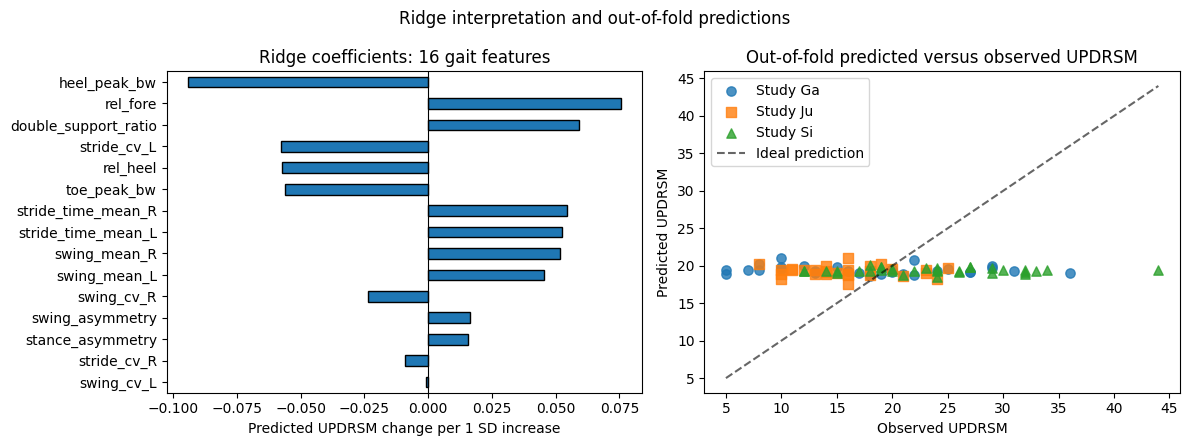

Saved Task 2 UPDRSM model.


In [ ]:
# =====================================================================
# STEP 17: Inspect Ridge coefficients and out-of-fold predictions
# =====================================================================

# Fit on all eligible baseline PD subjects for coefficient interpretation
ridge_16_fit = fit_grouped_ridge(
    pd_updrsm[gait_cols],
    pd_updrsm['updrsm'].to_numpy(dtype=float),
    pd_updrsm['subject_id'].to_numpy(),
)

ridge_pipeline = ridge_16_fit.best_estimator_
ridge_step = ridge_pipeline.named_steps['ridge']
imputer = ridge_pipeline.named_steps['simpleimputer']
feature_names = imputer.get_feature_names_out()

coef_series = pd.Series(ridge_step.coef_, index=feature_names)
coef_series = coef_series.sort_values(key=abs)
best_alpha = ridge_16_fit.best_params_['ridge__alpha']

print(f'STEP 17: Ridge coefficients (alpha = {best_alpha:.3g})')
print(coef_series.iloc[::-1].round(4))  # Largest absolute coefficients first

# Use held-out predictions already collected in Step 16
y_obs = pd_updrsm['updrsm'].to_numpy(dtype=float)
y_oof_ridge = oof_predictions[oof_key]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Coefficients are expressed per one training-set SD increase
coef_series.plot(kind='barh', ax=axes[0], edgecolor='black')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Ridge coefficients: 16 gait features')
axes[0].set_xlabel('Predicted UPDRSM change per 1 SD increase')

for study, marker in [('Ga', 'o'), ('Ju', 's'), ('Si', '^')]:
    mask = (pd_updrsm['study'] == study).to_numpy()
    axes[1].scatter(
        y_obs[mask], y_oof_ridge[mask],
        label=f'Study {study}', marker=marker, alpha=0.8, s=45,
    )

# Extend the ideal prediction line across both data ranges
lower = min(y_obs.min(), y_oof_ridge.min())
upper = max(y_obs.max(), y_oof_ridge.max())

axes[1].plot(
    [lower, upper], [lower, upper],
    'k--', alpha=0.6, label='Ideal prediction',
)
axes[1].set_title('Out-of-fold predicted versus observed UPDRSM')
axes[1].set_xlabel('Observed UPDRSM')
axes[1].set_ylabel('Predicted UPDRSM')
axes[1].legend()

fig.suptitle('Ridge interpretation and out-of-fold predictions')
plt.tight_layout()
plt.savefig('ridge_interpretation.png', dpi=300)
plt.show()

task2_updrsm_saved = {
    'model': ridge_pipeline,
    'features': list(gait_cols),
    'target': 'updrsm',
}

joblib.dump(
    task2_updrsm_saved,
    'task2_updrsm_model.joblib',
    compress=3,
)
print("Saved Task 2 UPDRSM model.")

In [ ]:
# =====================================================================
# STEP 18: Evaluate UPDRSM prediction on an unseen study
# =====================================================================
# Train on two source studies and test on the remaining study.
# Use baseline walks only, with one row per subject.

study_cv = LeaveOneGroupOut()
study_folds = study_cv.split(pd_updrsm, groups=pd_updrsm['study'])
loso_results = []

for tr_idx, te_idx in study_folds:
    train_fold = pd_updrsm.iloc[tr_idx]
    test_fold = pd_updrsm.iloc[te_idx]
    test_study = test_fold['study'].iloc[0]

    y_train_reg = train_fold['updrsm'].to_numpy(dtype=float)
    y_true_reg = test_fold['updrsm'].to_numpy(dtype=float)
    groups_train = train_fold['subject_id'].to_numpy()

    for feat_name, feat_cols in feature_sets_part_b.items():
        X_train_reg = train_fold[feat_cols]
        X_test_reg = test_fold[feat_cols]

        for model_name, model in regression_models.items():
            if model_name == 'Ridge Regression (L2)':
                fitted_model = fit_grouped_ridge(
                    X_train_reg, y_train_reg, groups_train
                )
            else:
                fitted_model = clone(model)
                fitted_model.fit(X_train_reg, y_train_reg)

            y_pred_reg = fitted_model.predict(X_test_reg)

            loso_results.append({
                'Held-Out Study': test_study,
                'Features': feat_name,
                'Model': model_name,
                'MAE': mean_absolute_error(y_true_reg, y_pred_reg),
                'RMSE': np.sqrt(mean_squared_error(y_true_reg, y_pred_reg)),
                'R2': r2_score(y_true_reg, y_pred_reg),
            })

loso_df = pd.DataFrame(loso_results)

print('STEP 18: Leave-one-study-out evaluation for UPDRSM')
display(loso_df.round(3))

STEP 18: Leave-one-study-out evaluation for UPDRSM


,Held-Out Study,Features,Model,MAE,RMSE,R2
0,Ga,16 gait features,Constant-Score Baseline,7.136,8.528,-0.064
1,Ga,16 gait features,Ridge Regression (L2),7.141,8.592,-0.080
2,Ga,16 gait features,Random Forest,7.583,9.102,-0.212
3,Ga,48 gait + sensor features,Constant-Score Baseline,7.136,8.528,-0.064
4,Ga,48 gait + sensor features,Ridge Regression (L2),7.763,9.194,-0.236
5,Ga,48 gait + sensor features,Random Forest,8.225,9.556,-0.336
6,Ju,16 gait features,Constant-Score Baseline,5.944,6.831,-1.346
7,Ju,16 gait features,Ridge Regression (L2),5.875,6.776,-1.309
8,Ju,16 gait features,Random Forest,5.767,6.689,-1.250
9,Ju,48 gait + sensor features,Constant-Score Baseline,5.944,6.831,-1.346


In [ ]:
# =====================================================================
# STEP 19: Predict Hoehn–Yahr stage using Random Forest
# =====================================================================

# Use PD subjects with a recorded H&Y stage and one baseline walk each
hy_data = base_df.loc[
    (base_df['label'] == 1) & base_df['hy'].notna()
].reset_index(drop=True)

assert hy_data['subject_id'].is_unique, 'Use one baseline walk per person.'

print(f'H&Y stage counts (n = {len(hy_data)}):')
print(hy_data['hy'].value_counts().sort_index())

# Encode the observed stages as classification labels
stage_codes = {2.0: 0, 2.5: 1, 3.0: 2}
y_hy = hy_data['hy'].map(stage_codes)

if y_hy.isna().any():
    raise ValueError('Unexpected H&Y stages found; check the stage counts.')

y_hy = y_hy.astype(int)

# One row per subject means these folds also separate subjects
hy_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
hy_folds = list(hy_cv.split(hy_data, y_hy))

hy_baseline = DummyClassifier(strategy='most_frequent')
hy_rf = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=3,
        class_weight='balanced',
        random_state=SEED,
    ),
)

# Each entry gives the feature label, model label, estimator, and columns
# The majority baseline ignores the feature values
hy_experiments = [
    ('Not applicable', 'Majority baseline', hy_baseline, gait_cols),
    ('16 gait features', 'Random Forest', hy_rf, gait_cols),
    ('32 sensor features', 'Random Forest', hy_rf, sensor_cols),
    ('48 gait + sensor features', 'Random Forest', hy_rf, all_cols),
]

hy_scoring = {
    'Accuracy': 'accuracy',
    'Balanced accuracy': 'balanced_accuracy',
    'Macro F1': make_scorer(f1_score, average='macro', zero_division=0),
}

hy_results = []

for feature_name, model_name, model, feature_cols in hy_experiments:
    scores = cross_validate(
        model,
        hy_data[feature_cols],
        y_hy,
        cv=hy_folds,
        scoring=hy_scoring,
        error_score='raise',
    )

    row = {'Features': feature_name, 'Model': model_name}

    for metric in hy_scoring:
        values = scores['test_' + metric]
        row[metric] = (
            f'{values.mean():.3f} ± {values.std(ddof=1):.3f}'
        )

    hy_results.append(row)

hy_results_df = pd.DataFrame(hy_results)

print('STEP 19: Five-fold CV for H&Y classification (mean ± 1 SD)')
display(hy_results_df)

# Final fit of the gait-feature RF configuration evaluated in Step 19
hy_final_model = clone(hy_rf)
hy_final_model.fit(hy_data[gait_cols], y_hy)

task2_hy_saved = {
    'model': hy_final_model,
    'features': list(gait_cols),
    'target': 'hy',
    # Convert predicted class codes back to actual H&Y stages
    'code_to_stage': {
        code: stage for stage, code in stage_codes.items()
    },
}

joblib.dump(
    task2_hy_saved,
    'task2_hy_model.joblib',
    compress=3,
)
print("Saved Task 2 H&Y model.")

H&Y stage counts (n = 93):
hy
2.0    55
2.5    28
3.0    10
Name: count, dtype: int64
STEP 19: Five-fold CV for H&Y classification (mean ± 1 SD)


,Features,Model,Accuracy,Balanced accuracy,Macro F1
0,Not applicable,Majority baseline,0.592 ± 0.018,0.333 ± 0.000,0.248 ± 0.005
1,16 gait features,Random Forest,0.580 ± 0.138,0.479 ± 0.160,0.481 ± 0.179
2,32 sensor features,Random Forest,0.517 ± 0.125,0.338 ± 0.108,0.321 ± 0.115
3,48 gait + sensor features,Random Forest,0.657 ± 0.084,0.553 ± 0.094,0.571 ± 0.106


Saved Task 2 H&Y model.


H&Y Classification — Out-of-Fold Results
Accuracy: 0.656
Balanced accuracy: 0.555
Macro F1: 0.588
Stage MAE: 0.188


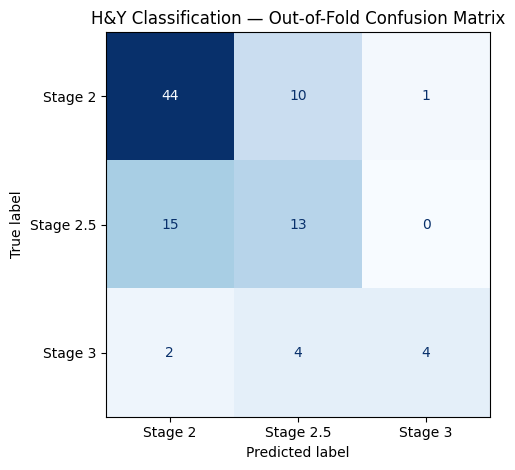


Performance by H&Y stage:
              precision    recall  f1-score   support

     Stage 2       0.72      0.80      0.76        55
   Stage 2.5       0.48      0.46      0.47        28
     Stage 3       0.80      0.40      0.53        10

    accuracy                           0.66        93
   macro avg       0.67      0.55      0.59        93
weighted avg       0.66      0.66      0.65        93



In [ ]:

# =====================================================================
# STEP 19.5: Evaluate H&Y classification in more detail
# =====================================================================

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    mean_absolute_error,
    balanced_accuracy_score,
    f1_score,
    accuracy_score
)

# 1. Generate out-of-fold predictions
# Each patient is predicted by a model that did not train on them.
y_hy_pred = cross_val_predict(
    hy_rf,
    hy_data[all_cols],
    y_hy,
    cv=hy_folds
)

# 2. Convert class codes back to actual H&Y stages
code_to_stage = {0: 2.0, 1: 2.5, 2: 3.0}

actual_stages = y_hy.map(code_to_stage).to_numpy()
predicted_stages = pd.Series(y_hy_pred).map(code_to_stage).to_numpy()

# 3. Calculate overall out-of-fold metrics
print("H&Y Classification — Out-of-Fold Results")
print("Accuracy:",
      round(accuracy_score(y_hy, y_hy_pred), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_hy, y_hy_pred), 3))
print("Macro F1:",
      round(f1_score(y_hy, y_hy_pred, average='macro'), 3))
print("Stage MAE:",
      round(mean_absolute_error(actual_stages, predicted_stages), 3))

# 4. Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_hy,
    y_hy_pred,
    labels=[0, 1, 2],
    display_labels=['Stage 2', 'Stage 2.5', 'Stage 3'],
    cmap='Blues',
    colorbar=False
)

plt.title('H&Y Classification — Out-of-Fold Confusion Matrix')
plt.tight_layout()
plt.savefig('hy_confusion.png', dpi=300)
plt.show()

# 5. Show performance for each severity stage
from sklearn.metrics import classification_report

print("\nPerformance by H&Y stage:")
print(classification_report(
    y_hy,
    y_hy_pred,
    labels=[0, 1, 2],
    target_names=['Stage 2', 'Stage 2.5', 'Stage 3'],
    zero_division=0
))


In [ ]:

# Compare ordinal error against the majority baseline

baseline_pred_stages = np.full(len(actual_stages), 2.0)

baseline_stage_mae = mean_absolute_error(
    actual_stages,
    baseline_pred_stages
)

model_stage_mae = mean_absolute_error(
    actual_stages,
    predicted_stages
)

print("Majority baseline Stage MAE:", round(baseline_stage_mae, 3))
print("Random Forest Stage MAE:", round(model_stage_mae, 3))
print("Improvement:",
      round(baseline_stage_mae - model_stage_mae, 3))


Majority baseline Stage MAE: 0.258
Random Forest Stage MAE: 0.188
Improvement: 0.07


In [ ]:
hy_final_model = clone(hy_rf)
hy_final_model.fit(hy_data[all_cols], y_hy)

task2_hy_saved = {
    'model': hy_final_model,
    'features': list(all_cols),
    'target': 'hy',
    'code_to_stage': {
        code: stage for stage, code in stage_codes.items()
    },
}

joblib.dump(
    task2_hy_saved,
    'task2_hy_model.joblib',
    compress=3,
)

print("Final model:", type(hy_final_model.named_steps['randomforestclassifier']).__name__)
print("Number of features:", len(task2_hy_saved['features']))
print("Features match:", task2_hy_saved['features'] == list(all_cols))
print("Stage mapping:", task2_hy_saved['code_to_stage'])

Final model: RandomForestClassifier
Number of features: 47
Features match: True
Stage mapping: {0: 2.0, 1: 2.5, 2: 3.0}


STEP 21: UPDRSM prediction errors by study


,Patients,Actual_Mean,Predicted_Mean,Mean_Error,MAE
Study,,,,,
Ga,29,17.897,19.449,1.552,7.124
Ju,29,15.793,19.246,3.453,4.934
Si,33,23.667,19.372,-4.294,6.479



Overall out-of-fold performance:
MAE: 6.192
RMSE: 7.664
R2: -0.013


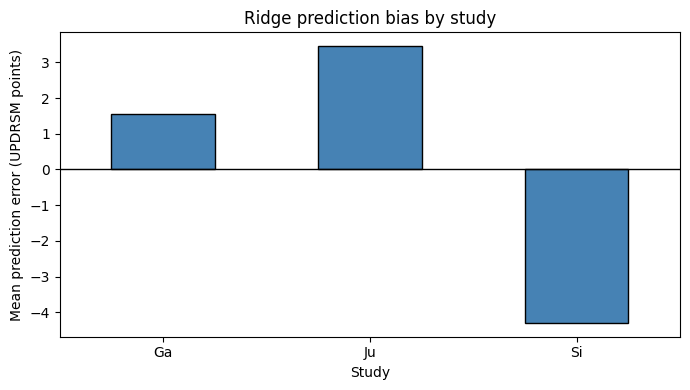

In [ ]:

# =====================================================================
# STEP 21: Analyse UPDRSM prediction errors by study
# =====================================================================

# Retrieve actual and out-of-fold predicted UPDRSM scores
y_actual = pd_updrsm['updrsm'].to_numpy(dtype=float)
y_predicted = oof_predictions[oof_key]

# Create a table containing each patient's prediction
error_df = pd.DataFrame({
    'Study': pd_updrsm['study'],
    'Actual_UPDRSM': y_actual,
    'Predicted_UPDRSM': y_predicted
})

# Positive error = overprediction
# Negative error = underprediction
error_df['Error'] = (
    error_df['Predicted_UPDRSM'] - error_df['Actual_UPDRSM']
)

error_df['Absolute_Error'] = error_df['Error'].abs()

# Calculate performance separately for each study
study_error_summary = error_df.groupby('Study').agg(
    Patients=('Error', 'count'),
    Actual_Mean=('Actual_UPDRSM', 'mean'),
    Predicted_Mean=('Predicted_UPDRSM', 'mean'),
    Mean_Error=('Error', 'mean'),
    MAE=('Absolute_Error', 'mean')
)

print("STEP 21: UPDRSM prediction errors by study")
display(study_error_summary.round(3))

# Overall out-of-fold performance
print("\nOverall out-of-fold performance:")
print("MAE:", round(mean_absolute_error(
    y_actual, y_predicted
), 3))

print("RMSE:", round(np.sqrt(mean_squared_error(
    y_actual, y_predicted
)), 3))

print("R2:", round(r2_score(
    y_actual, y_predicted
), 3))

# Visualise directional prediction errors
plt.figure(figsize=(7, 4))

study_error_summary['Mean_Error'].plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Study')
plt.ylabel('Mean prediction error (UPDRSM points)')
plt.title('Ridge prediction bias by study')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('updrsm_study_errors.png', dpi=300)
plt.show()
